# Representation Evidence — Five-Seed Analysis

Regenerates the figures and detailed evidence tables from the saved representation-diagnostics results. No model training occurs in this notebook.

**Inputs:** `outputs/medium_world/experiments/representation_diagnostics/five_seeds/` and the frozen Medium World dataset. **Outputs:** `evidence_figures/` and `evidence_tables/` under that same experiment directory.

The code and the plotted numbers are the research record. Record Python/GPU/library information once in the repository `README.md`, not in a separate machine-readable manifest. Quantities involving the same scene or the same seed should not be mistaken for independent observations.

This notebook reproduces the *six earlier figures* and *eight earlier detailed evidence tables*, plus a supplemental spectral-cluster figure and intermediate tables. The narrative Markdown report remains a separate document.

In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().resolve().parent.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

DATA_DIR = PROJECT_ROOT / "outputs/medium_world/dataset"
OUT_DIR = PROJECT_ROOT / "outputs/medium_world/experiments/representation_diagnostics/five_seeds"
FIG_DIR = OUT_DIR / "evidence_figures"
TABLE_DIR = OUT_DIR / "evidence_tables"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

SEEDS = (42, 43, 44, 45, 46)
SCHEDULES = ("mixed", "prereq_mixed_pair_focus")
STEPS = (5400, 7200, 9000)
SPLITS = ("id_dev", "ood_dev")
HOLDOUT = {("red", "crescent"), ("blue", "square"),
           ("green", "circle"), ("purple", "triangle")}

print("Root:", PROJECT_ROOT)
print("Results:", OUT_DIR)

Root: C:\Users\Quoc Thai\Downloads\AI\AIO\Conquer\AIO Conquer 5 - visual_world\The-order-of-Learning
Results: C:\Users\Quoc Thai\Downloads\AI\AIO\Conquer\AIO Conquer 5 - visual_world\The-order-of-Learning\outputs\medium_world\experiments\representation_diagnostics\five_seeds


In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image as NotebookImage
from sklearn.metrics import adjusted_mutual_info_score, roc_auc_score

from src.medium_visual_world.world import from_dict
from src.medium_visual_world.render import render


def read_csv(name, usecols=None):
    return pd.read_csv(OUT_DIR / name, usecols=usecols)


def read_npz(name, key):
    with np.load(OUT_DIR / name, allow_pickle=False) as archive:
        return archive[key].copy()


def save_table(table, filename):
    path = TABLE_DIR / filename
    table.to_csv(path, index=False)
    print(f"Table: {filename} ({len(table):,} rows)")
    return path


def save_figure(figure, filename):
    path = FIG_DIR / filename
    figure.savefig(path, dpi=170, bbox_inches="tight")
    display(NotebookImage(filename=str(path)))
    plt.close(figure)
    print(f"Figure: {filename}")


def run_key(schedule, seed, step):
    return schedule, int(seed), int(step)

## 1. Load the saved experiment and original questions

The 30 checkpoint identities are used to label runs. No environment manifest or automatic compatibility gates are created.

In [3]:
manifest = read_csv("checkpoint_manifest.csv")
with (DATA_DIR / "id_dev.jsonl").open(encoding="utf-8") as stream:
    id_rows = [json.loads(line) for line in stream if line.strip()]
with (DATA_DIR / "ood_dev.jsonl").open(encoding="utf-8") as stream:
    ood_rows = [json.loads(line) for line in stream if line.strip()]
scenes = {row["scene_id"]: row["scene"] for row in id_rows}
print("Saved checkpoint records:", len(manifest))
print("ID questions:", len(id_rows), "| OOD questions:", len(ood_rows))

Saved checkpoint records: 30
ID questions: 1024 | OOD questions: 400


## 2. Original-task learning trajectories — regenerated from per-question predictions

The expanded same-scene grid is **not** a balanced benchmark: Color/Shape questions are repeated across irrelevant target choices. We reconstruct each original ID-dev question's exact key, join it to the expanded grid, check label equality, and only then calculate accuracy. Results are cross-checked against the original checkpoint performance export.

In [4]:
task_key = {
    "color": lambda args: args[0],
    "shape": lambda args: args[0],
    "conjunction": lambda args: "_".join(args),
    "pair": lambda args: "_".join(args),
}
original_questions = pd.DataFrame([
    {
        "question_key": f"{row['scene_id']}|{row['template']}|"
                        f"{task_key[row['template']](row['question']['args'])}",
        "task": row["template"], "reference_label": int(row["label"])
    }
    for row in id_rows
])
assert original_questions.question_key.is_unique

metrics = []
for schedule in SCHEDULES:
    for seed in SEEDS:
        for step in STEPS:
            filename = f"same_scene_id_dev_{schedule}_seed{seed}_step{step}.csv"
            d = read_csv(filename, usecols=[
                "question_key", "task", "label", "correct", "cross_entropy",
                "checkpoint_sha256"
            ])
            d = d.drop_duplicates("question_key", keep="first")
            joined = original_questions.merge(d, on=["question_key", "task"], how="left", validate="one_to_one")
            if joined.label.isna().any():
                raise ValueError("Some original questions are missing from the saved grid")
            for task, part in joined.groupby("task"):
                metrics.append({
                    "schedule": schedule, "seed": seed, "step": step, "task": task,
                    "accuracy": float(part.correct.mean()),
                    "cross_entropy": float(part.cross_entropy.mean()),
                    "n_questions": len(part)
                })
original_metrics = pd.DataFrame(metrics)
old = read_csv("original_checkpoint_performance.csv").query('split == "id_dev"')
check = original_metrics.merge(old, on=["schedule", "seed", "step", "task"], validate="one_to_one", suffixes=("_recomputed", "_previous"))
check["accuracy_delta"] = check.accuracy_recomputed - check.accuracy_previous
check["cross_entropy_delta"] = check.cross_entropy_recomputed - check.cross_entropy_previous
check["n_prediction_disagreements"] = (np.abs(check.accuracy_delta) * 256).round().astype(int)
# Retain mismatches as results; do not hide them or stop the analysis.
save_table(check, "original_vs_same_scene_crosscheck.csv")
print("Cross-check: groups with prediction-count differences:",
      int(check.n_prediction_disagreements.gt(0).sum()))
print("Largest absolute CE discrepancy:", check.cross_entropy_delta.abs().max())
save_table(original_metrics, "original_id_performance_recomputed.csv")
display(original_metrics.groupby(["schedule", "step", "task"]).accuracy.agg(["mean", "std"]).round(4))

Table: original_vs_same_scene_crosscheck.csv (120 rows)
Cross-check: groups with prediction-count differences: 1
Largest absolute CE discrepancy: 2.887452207633867e-05
Table: original_id_performance_recomputed.csv (120 rows)


mean     std
schedule                step task                       
mixed                   5400 color        0.9828  0.0191
                             conjunction  0.7992  0.0189
                             pair         0.5773  0.0312
                             shape        0.6383  0.0251
                        7200 color        0.9922  0.0073
                             conjunction  0.7953  0.0169
                             pair         0.6078  0.0480
                             shape        0.6508  0.0155
                        9000 color        0.9922  0.0078
                             conjunction  0.7977  0.0157
                             pair         0.6203  0.0447
                             shape        0.6781  0.0131
prereq_mixed_pair_focus 5400 color        0.9922  0.0062
                             conjunction  0.8055  0.0150
                             pair         0.5016  0.0065
                             shape        0.6438  0.0294
                        7200 color        0.9430  0.0540
                             conjunction  0.7047  0.0500
                             pair         0.6750  0.0447
                             shape        0.5711  0.0382
                        9000 color        0.9938  0.0045
                             conjunction  0.8070  0.0217
                             pair         0.6305  0.0140
                             shape        0.6688  0.0180

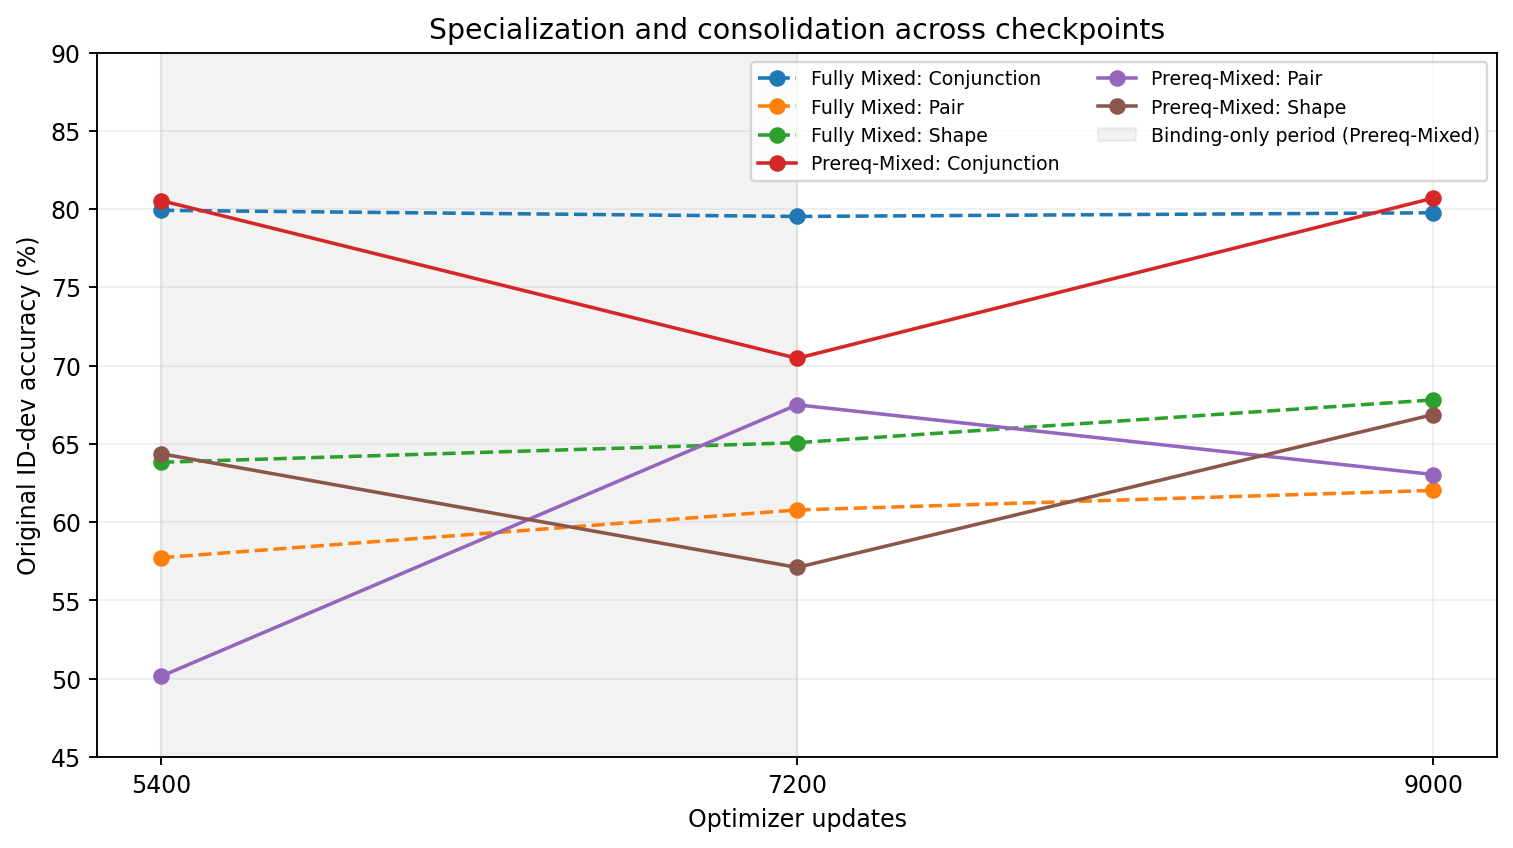

Figure: representation_stage_trajectories.png


In [5]:
fig, ax = plt.subplots(figsize=(9, 5.1))
for (schedule, task), part in original_metrics.query(
    'task in ["shape", "conjunction", "pair"]'
).groupby(["schedule", "task"]):
    means = part.groupby("step").accuracy.mean().reindex(STEPS)
    name = ("Prereq-Mixed" if schedule.startswith("prereq") else "Fully Mixed")
    ax.plot(STEPS, 100 * means.values, marker="o",
            linestyle="-" if schedule.startswith("prereq") else "--",
            label=f"{name}: {task.capitalize()}")
ax.axvspan(5400, 7200, color="gray", alpha=0.10,
           label="Binding-only period (Prereq-Mixed)")
ax.set(xlabel="Optimizer updates", ylabel="Original ID-dev accuracy (%)",
       title="Specialization and consolidation across checkpoints")
ax.set_xticks(STEPS)
ax.set_ylim(45, 90)
ax.grid(alpha=0.2)
ax.legend(fontsize=8, ncol=2)
fig.tight_layout()
save_figure(fig, "representation_stage_trajectories.png")

## 3. Counterfactual evidence with exact sample support

All three edits are No→Yes changes for their target questions. `both_correct` is more stringent than `direction_correct`. Report each run's sample count and compute comparisons at the **seed level**; a single scene can generate multiple counterfactual pairs. This is a diagnostic comparison, not a randomized causal effect between Color and Shape interventions.

In [6]:
counter_rows = []
for schedule in SCHEDULES:
    for seed in SEEDS:
        for step in STEPS:
            d = read_csv(f"counterfactual_id_dev_{schedule}_seed{seed}_step{step}.csv")
            assert len(d) > 0

            assert (d.label_after.eq(1) & d.label_before.eq(0)).all()
            for edit, part in d.groupby("edit"):
                counter_rows.append({
                    "schedule": schedule, "seed": seed, "step": step, "edit": edit,
                    "n_edits": len(part), "n_scenes": part.scene_id.nunique(),
                    "both_correct": float(part.both_correct.mean()),
                    "direction_correct": float(part.direction_correct.mean()),
                    "mean_delta_yes": float(part.delta_yes.mean())
                })
counter_metrics = pd.DataFrame(counter_rows)
save_table(counter_metrics, "counterfactual_run_level.csv")
final_counter = counter_metrics.query('step == 9000')
display(final_counter.groupby(["schedule", "edit"])
        [["both_correct", "direction_correct", "n_edits", "n_scenes"]]
        .agg(["mean", "std"]).round(4))

Table: counterfactual_run_level.csv (90 rows)


both_correct         direction_correct  \
                                             mean     std              mean   
schedule                edit                                                  
mixed                   binding_swap       0.2327  0.0410            0.6429   
                        color_insert       0.8820  0.0305            0.9999   
                        shape_insert       0.0833  0.0225            0.6009   
prereq_mixed_pair_focus binding_swap       0.2482  0.0296            0.6737   
                        color_insert       0.8855  0.0467            0.9997   
                        shape_insert       0.0942  0.0389            0.6444   

                                             n_edits      n_scenes       
                                         std    mean  std     mean  std  
schedule                edit                                             
mixed                   binding_swap  0.0565  1132.0  0.0    246.0  0.0  
                        color_insert  0.0003  1390.0  0.0    252.0  0.0  
                        shape_insert  0.0546   675.0  0.0    209.0  0.0  
prereq_mixed_pair_focus binding_swap  0.0328  1132.0  0.0    246.0  0.0  
                        color_insert  0.0004  1390.0  0.0    252.0  0.0  
                        shape_insert  0.0407   675.0  0.0    209.0  0.0

### Invariance and same-scene logic — direct behavioral controls

Compute these values from the **individual** `invariance_*` and `logical_consistency_*` files. Every invariance test preserves its oracle label, while logical consistency is evaluated on each unique scene × Color × Shape query tuple (not the duplicated Color/Shape rows in the expanded task grid). The tables report both scene counts and task-dependent prediction errors.

In [7]:
invariance_rows = []
logical_rows = []
for schedule in SCHEDULES:
    for seed in SEEDS:
        for step in STEPS:
            invariant = read_csv(
                f"invariance_id_dev_{schedule}_seed{seed}_step{step}.csv"
            )

            assert (invariant.label_after == invariant.label_before).all()
            for edit, part in invariant.groupby("edit"):
                invariance_rows.append({
                    "schedule": schedule, "seed": seed, "step": step,
                    "edit": edit, "n_queries": len(part),
                    "n_scenes": part.scene_id.nunique(),
                    "prediction_flip_rate": float(part.prediction_flipped.mean()),
                    "mean_abs_delta_yes": float(part.abs_delta_yes.mean())
                })

            logical = read_csv(
                f"logical_consistency_id_dev_{schedule}_seed{seed}_step{step}.csv"
            )
            assert not logical.duplicated(["scene_id", "color", "shape"]).any()
            assert len(logical) == len(scenes) * len(HOLDOUT | {
                (color, shape) for color in (
                    "red", "blue", "green", "yellow", "purple")
                for shape in ("circle", "square", "triangle", "crescent")
            })
            logical_rows.append({
                "schedule": schedule, "seed": seed, "step": step,
                "n_queries": len(logical), "n_scenes": logical.scene_id.nunique(),
                "violates_binding_implies_attributes": float(
                    logical.violates_binding_implies_attributes.mean()),
                "violates_conjunction_definition": float(
                    logical.violates_conjunction_definition.mean()),
                "missed_binding_despite_correct_prerequisites": float(
                    logical.missed_binding_despite_correct_prerequisites.mean())
            })

invariance_metrics = pd.DataFrame(invariance_rows)
logical_metrics = pd.DataFrame(logical_rows)
save_table(invariance_metrics, "invariance_by_run.csv")
save_table(logical_metrics, "logical_consistency_by_run.csv")
display(invariance_metrics.query('step == 9000')
        .groupby(["schedule", "edit"])
        .prediction_flip_rate.agg(["mean", "std"]).round(4))
display(logical_metrics.query('step == 9000')
        .groupby("schedule")
        [["violates_binding_implies_attributes",
          "violates_conjunction_definition",
          "missed_binding_despite_correct_prerequisites"]]
        .agg(["mean", "std"]).round(4))

Table: invariance_by_run.csv (150 rows)
Table: logical_consistency_by_run.csv (30 rows)


mean     std
schedule                edit                                               
mixed                   binding_swap_invariance_color        0.0221  0.0189
                        binding_swap_invariance_conjunction  0.1461  0.0211
                        binding_swap_invariance_shape        0.1843  0.0186
                        color_insert_invariance_shape        0.2227  0.0253
                        shape_insert_invariance_color        0.0107  0.0046
prereq_mixed_pair_focus binding_swap_invariance_color        0.0237  0.0114
                        binding_swap_invariance_conjunction  0.1581  0.0412
                        binding_swap_invariance_shape        0.1901  0.0287
                        color_insert_invariance_shape        0.2345  0.0122
                        shape_insert_invariance_color        0.0116  0.0055

violates_binding_implies_attributes          \
                                                       mean     std   
schedule                                                              
mixed                                                0.1441  0.0399   
prereq_mixed_pair_focus                              0.1247  0.0525   

                        violates_conjunction_definition          \
                                                   mean     std   
schedule                                                          
mixed                                            0.2198  0.0277   
prereq_mixed_pair_focus                          0.2059  0.0223   

                        missed_binding_despite_correct_prerequisites          
                                                                mean     std  
schedule                                                                      
mixed                                                         0.1087  0.0159  
prereq_mixed_pair_focus                                       0.1094  0.0244

## 4. The eight head inputs — single-scalar AUC

For each task, calculate the ROC AUC of each original `head_f0`–`head_f7` scalar, separately per seed. As in the earlier visualization, use `max(AUC, 1−AUC)` to measure **direction-invariant separability**, not feature importance. For Color/Shape, remove duplicate `question_key` rows. For Binding, restrict to training-permitted target pairs where both requested attributes are present, contrasting true pairs with hard negatives.

In [8]:
from sklearn.metrics import roc_auc_score

head_records = []
for seed in SEEDS:
    schedule, step = "prereq_mixed_pair_focus", 9000
    head_cols = ["question_key", "scene_id", "task", "color", "shape",
                 "label", "logic_case", "heldout_target"]
    head_cols += [f"head_f{index}" for index in range(8)]
    d = read_csv(f"same_scene_id_dev_{schedule}_seed{seed}_step{step}.csv",
                 usecols=head_cols)

    for task in ("color", "shape", "conjunction", "pair"):
        part = d.loc[d.task == task].copy()
        if task in ("color", "shape"):
            part = part.drop_duplicates("question_key")
        elif task == "pair":
            part = part[(part.logic_case == "both_present") &
                        (~part.heldout_target.astype(bool))]
        else:
            part = part.loc[~part.heldout_target.astype(bool)]
        assert part.label.nunique() == 2, (seed, task, part.label.value_counts())
        for feature in range(8):
            x = part[f"head_f{feature}"].to_numpy(dtype=float)
            auc = (roc_auc_score(part.label, x) if np.ptp(x) > 1e-10
                   else float("nan"))
            head_records.append({
                "schedule": schedule, "seed": seed, "step": step,
                "task": task, "feature": feature, "n_questions": len(part),
                "auc_raw": auc,
                "auc_oriented": max(auc, 1 - auc) if np.isfinite(auc) else np.nan
            })
head_auc = pd.DataFrame(head_records)
save_table(head_auc, "head_feature_auc_by_seed.csv")
head_mean = head_auc.groupby(["task", "feature"]).auc_oriented.mean().unstack("feature")
display(head_mean.round(3))

Table: head_feature_auc_by_seed.csv (160 rows)


feature,0,1,2,3,4,5,6,7
task,,,,,,,,
color,0.887,0.793,NaN,NaN,0.726,0.770,NaN,NaN
conjunction,0.772,0.711,0.559,0.552,0.640,0.650,0.582,0.570
pair,0.554,0.551,0.527,0.523,0.571,0.545,0.526,0.552
shape,0.604,0.597,NaN,NaN,0.611,0.586,NaN,NaN


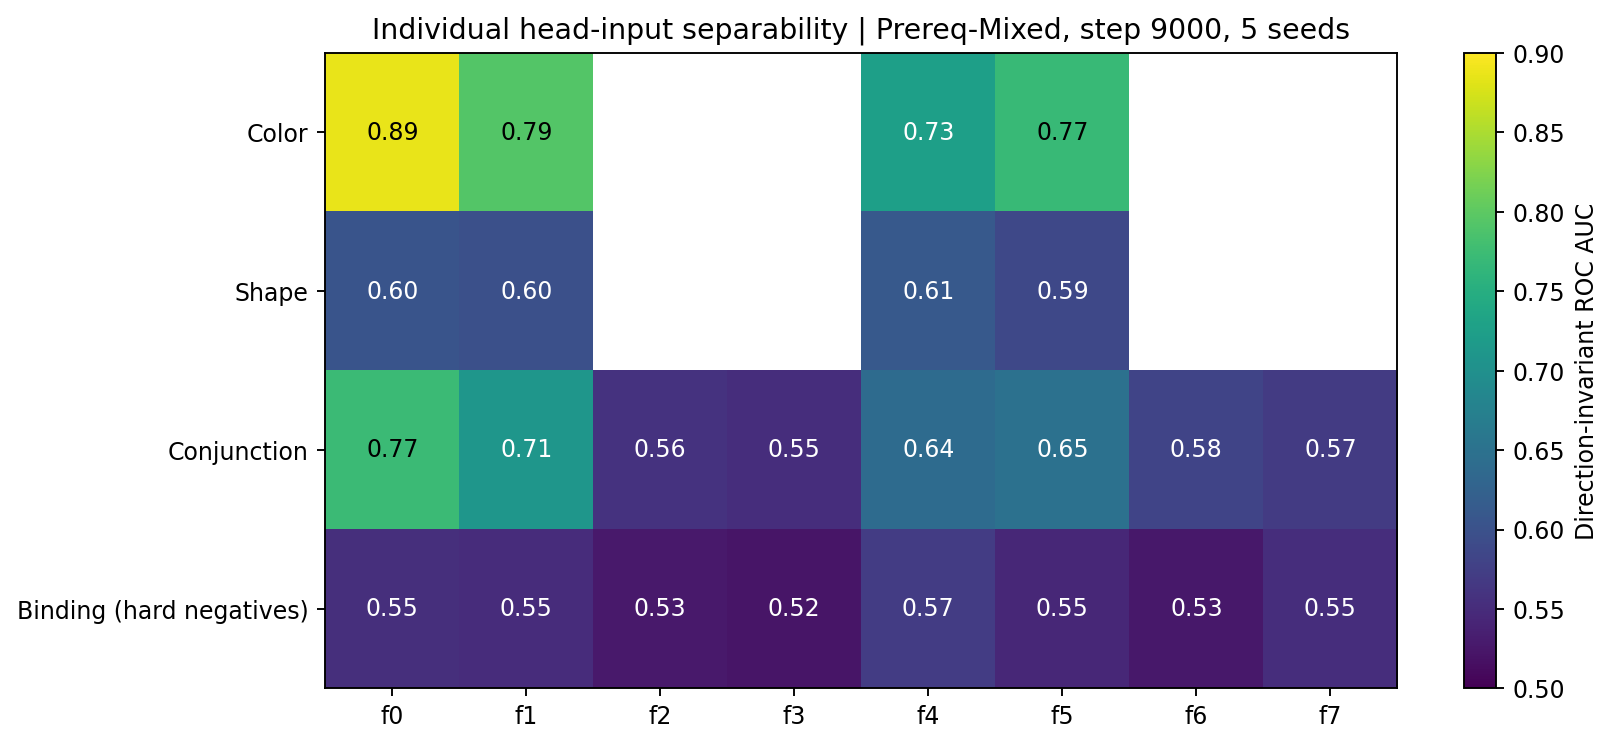

Figure: representation_head_feature_auc.png


In [9]:
tasks = ("color", "shape", "conjunction", "pair")
matrix = head_mean.reindex(index=tasks, columns=range(8)).to_numpy()
fig, ax = plt.subplots(figsize=(10, 4.5))
image = ax.imshow(matrix, vmin=0.5, vmax=0.9, cmap="viridis", aspect="auto")
ax.set_yticks(range(4), ["Color", "Shape", "Conjunction", "Binding (hard negatives)"])
ax.set_xticks(range(8), [f"f{j}" for j in range(8)])
ax.set_title("Individual head-input separability | Prereq-Mixed, step 9000, 5 seeds")
for i in range(4):
    for j in range(8):
        value = matrix[i, j]
        color = "black" if np.isfinite(value) and value > 0.73 else "white"
        ax.text(j, i, "—" if not np.isfinite(value) else f"{value:.2f}",
                ha="center", va="center", color=color)
fig.colorbar(image, ax=ax, label="Direction-invariant ROC AUC")
fig.tight_layout()
save_figure(fig, "representation_head_feature_auc.png")

## 5. Frozen object-level probes — Size and held-out combinations

The probe's input is a **fixed-ROI mean-pooled feature vector**, not the full token map. The training and random baselines each have a separately fitted probe. Therefore weak decoding can reflect the probe representation or training correlations, not necessarily absence of Shape information from the original ViT.

In [10]:
probe_rows = []
for schedule in SCHEDULES:
    for seed in SEEDS:
        filename = f"probe_predictions_{schedule}_seed{seed}_step9000.csv"
        d = read_csv(filename)

        part = d[(d.task == "shape") & (d.stage == "encoder") &
                 (d.split.isin(SPLITS))]
        assert part.baseline.isin(["random", "trained"]).all()
        probe_rows.append(part)
probes = pd.concat(probe_rows, ignore_index=True)
assert not probes.duplicated(["schedule", "seed", "step", "baseline", "split",
                              "scene_id", "object_index", "task", "stage"]).any()
probes["heldout_pair"] = [
    (color, shape) in HOLDOUT for color, shape in zip(probes.color, probes["shape"])
]
probe_by_pair = (
    probes.groupby(["schedule", "seed", "split", "baseline", "heldout_pair"])
    .agg(n_objects=("correct", "size"), n_scenes=("scene_id", "nunique"),
         accuracy=("correct", "mean")).reset_index()
)
save_table(probe_by_pair, "probe_heldout_accuracy_by_seed.csv")
display(probe_by_pair.groupby(["schedule", "split", "baseline", "heldout_pair"])
        .accuracy.agg(["mean", "std"]).round(4))

Table: probe_heldout_accuracy_by_seed.csv (60 rows)


mean     std
schedule                split   baseline heldout_pair                
mixed                   id_dev  random   False         0.5275  0.0198
                                trained  False         0.5380  0.0403
                        ood_dev random   False         0.5123  0.0191
                                         True          0.1588  0.0452
                                trained  False         0.5291  0.0462
                                         True          0.0713  0.0792
prereq_mixed_pair_focus id_dev  random   False         0.5275  0.0198
                                trained  False         0.5535  0.0372
                        ood_dev random   False         0.5123  0.0191
                                         True          0.1588  0.0452
                                trained  False         0.5388  0.0255
                                         True          0.0625  0.0352

Table: shape_radius_accuracy_by_seed.csv (80 rows)


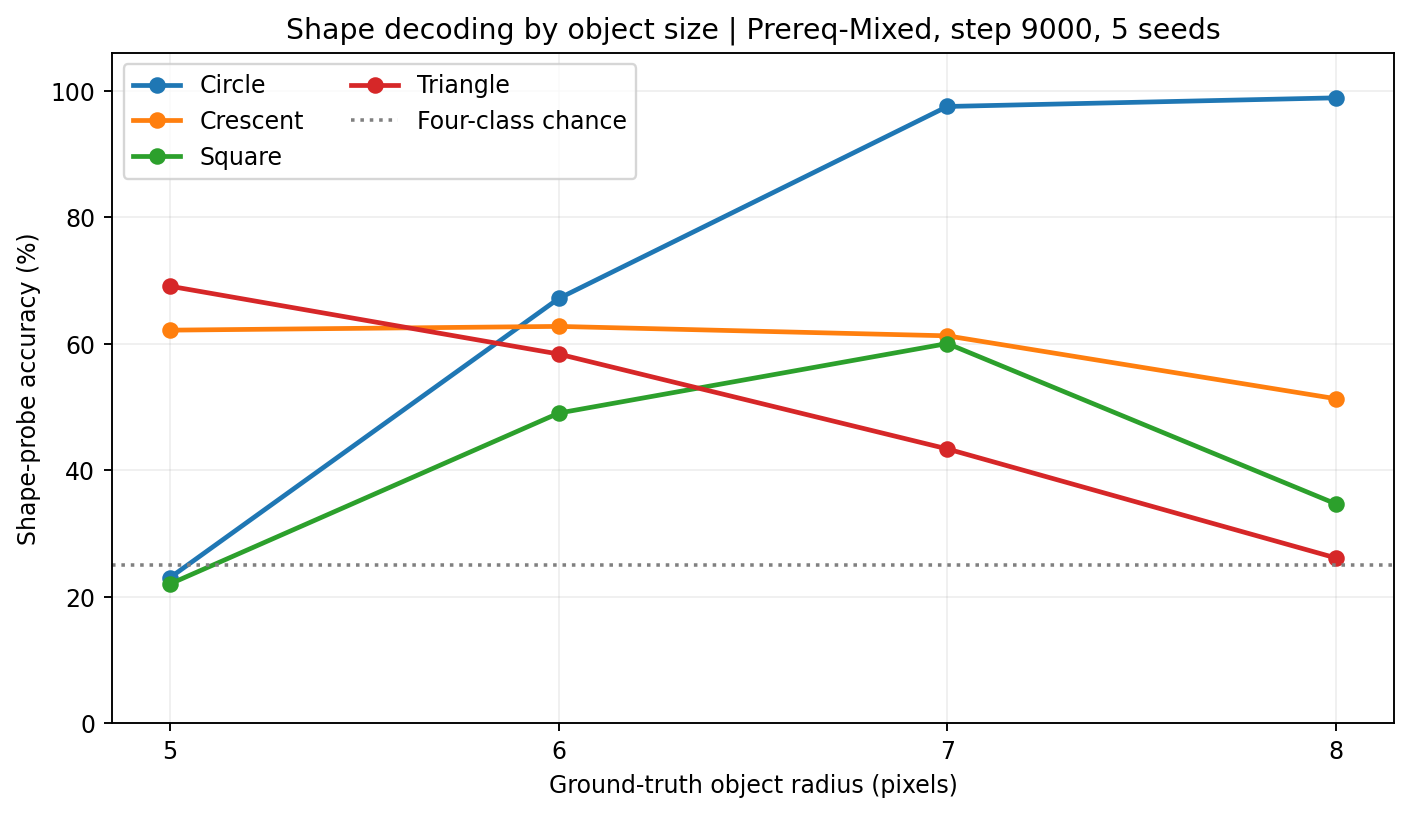

Figure: representation_shape_radius_effect.png


In [11]:
geometry = (
    probes[(probes.schedule == "prereq_mixed_pair_focus") &
           (probes.split == "id_dev") & (probes.baseline == "trained")]
    .groupby(["seed", "shape", "radius"])
    .agg(accuracy=("correct", "mean"), n_objects=("correct", "size"),
         n_scenes=("scene_id", "nunique")).reset_index()
)
previous_geometry = read_csv("probe_shape_by_geometry.csv")
previous_geometry = previous_geometry.query(
    'schedule == "prereq_mixed_pair_focus" and step == 9000 and '
    'stage == "encoder" and split == "id_dev"'
)
check = geometry.merge(previous_geometry, on=["seed", "shape", "radius"],
                       validate="one_to_one", suffixes=("", "_previous"))
save_table(geometry, "shape_radius_accuracy_by_seed.csv")

fig, ax = plt.subplots(figsize=(8.4, 4.9))
for shape, part in geometry.groupby("shape"):
    means = part.groupby("radius").accuracy.mean().reindex((5, 6, 7, 8))
    ax.plot(means.index, means.values * 100, "o-", linewidth=2,
            label=shape.capitalize())
ax.axhline(25, linestyle=":", color="gray", label="Four-class chance")
ax.set(xlabel="Ground-truth object radius (pixels)",
       ylabel="Shape-probe accuracy (%)",
       title="Shape decoding by object size | Prereq-Mixed, step 9000, 5 seeds")
ax.set_xticks((5, 6, 7, 8))
ax.set_ylim(0, 106)
ax.grid(alpha=0.2)
ax.legend(ncol=2)
fig.tight_layout()
save_figure(fig, "representation_shape_radius_effect.png")

Table: ood_shape_by_color_shape_seed.csv (200 rows)


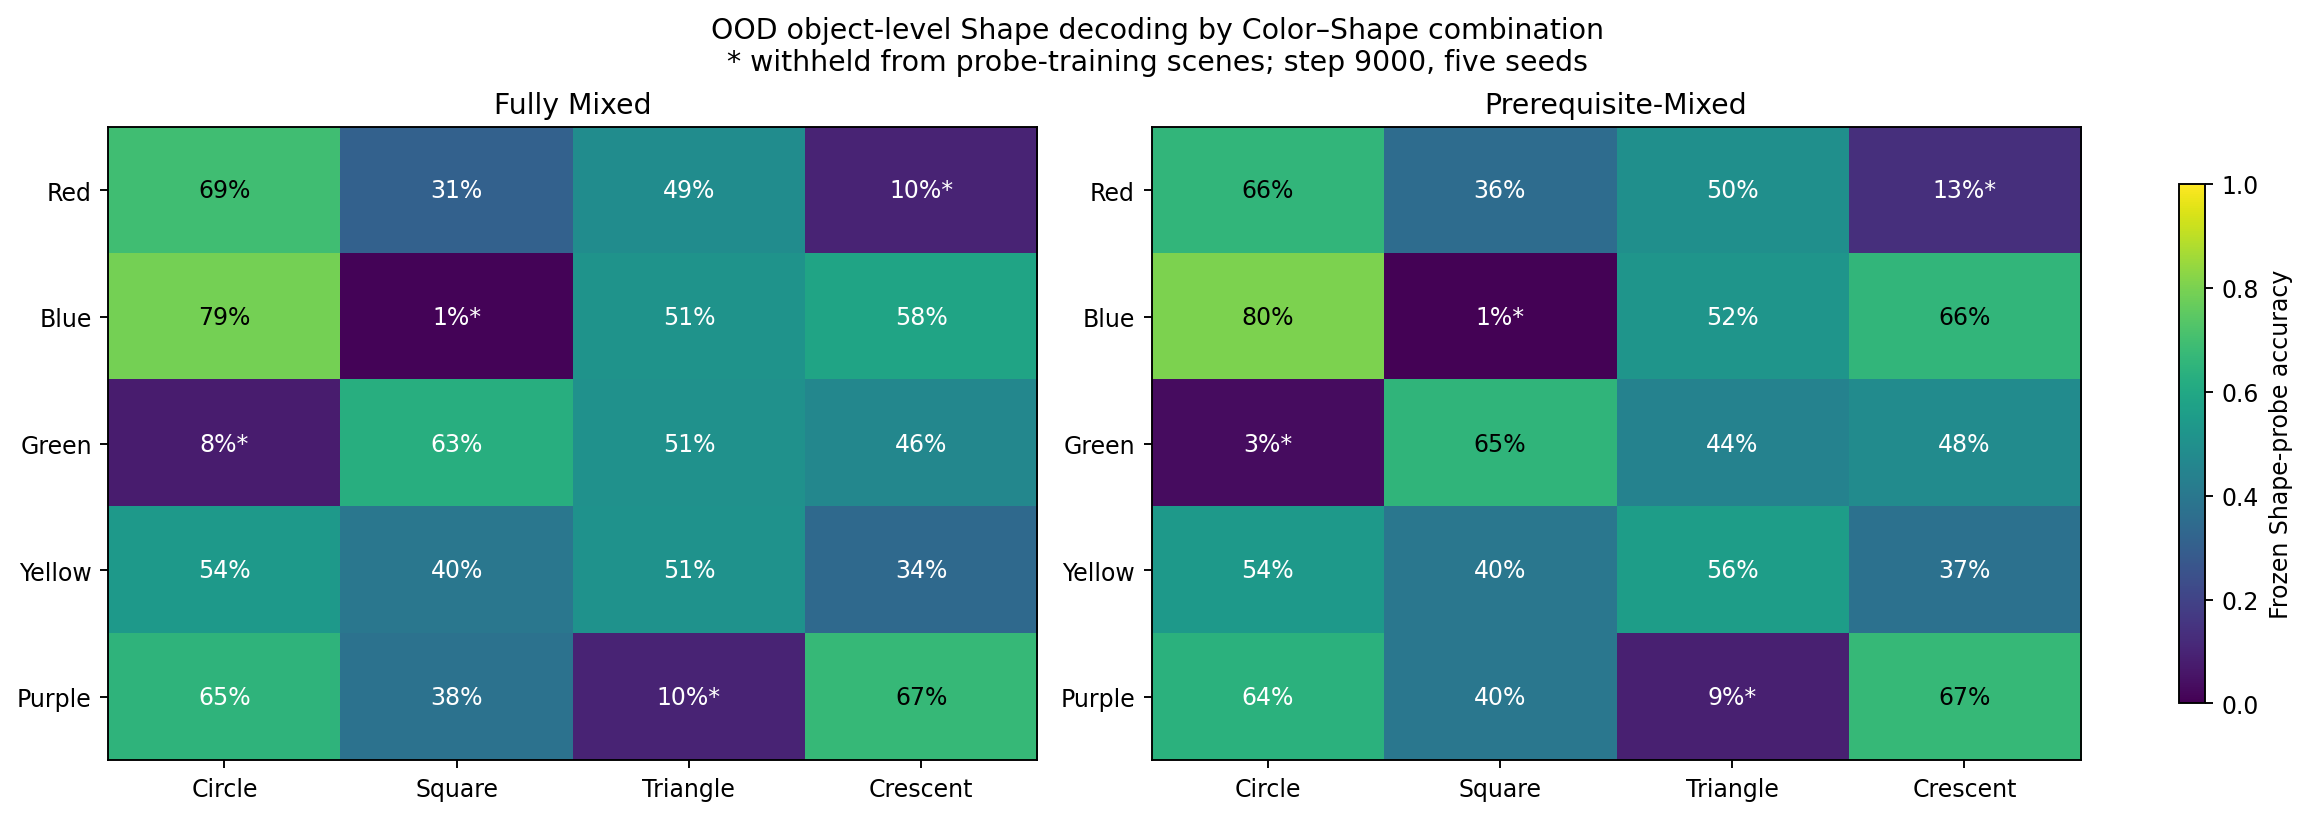

Figure: representation_probe_color_shape_heatmap.png


In [12]:
colors = ("red", "blue", "green", "yellow", "purple")
shapes = ("circle", "square", "triangle", "crescent")
by_combo = (
    probes[(probes.split == "ood_dev") & (probes.baseline == "trained")]
    .groupby(["schedule", "seed", "color", "shape"])
    .agg(accuracy=("correct", "mean"), n_objects=("correct", "size"))
    .reset_index()
)
save_table(by_combo, "ood_shape_by_color_shape_seed.csv")

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.7), constrained_layout=True)
for ax, schedule, name in zip(axes, SCHEDULES, ("Fully Mixed", "Prerequisite-Mixed")):
    subset = by_combo[by_combo.schedule == schedule]
    mean = subset.groupby(["color", "shape"]).accuracy.mean()
    matrix = np.array([[mean.get((c, s), np.nan) for s in shapes] for c in colors])
    image = ax.imshow(matrix, vmin=0, vmax=1, cmap="viridis", aspect="auto")
    ax.set_xticks(range(4), [s.title() for s in shapes])
    ax.set_yticks(range(5), [c.title() for c in colors])
    ax.set_title(name)
    for i, color in enumerate(colors):
        for j, shape in enumerate(shapes):
            value = matrix[i, j]
            marker = "*" if (color, shape) in HOLDOUT else ""
            ax.text(j, i, f"{100 * value:.0f}%{marker}",
                    ha="center", va="center",
                    color="white" if value < 0.65 else "black")
fig.colorbar(image, ax=axes, shrink=0.82, label="Frozen Shape-probe accuracy")
fig.suptitle("OOD object-level Shape decoding by Color–Shape combination\n"
             "* withheld from probe-training scenes; step 9000, five seeds")
save_figure(fig, "representation_probe_color_shape_heatmap.png")

## 6. Network Dissection-style concept overlap

The original diagnostic computes channel-to-concept IoU using renderer-derived masks and activation thresholds calibrated on training scenes. This notebook reads **raw per-unit** IoUs, recomputes the maximum per concept, compares trained and random features, and visualizes all 48 fused channels for a predetermined model (Prereq-Mixed, seed 42, step 9,000). We use both 0.99 and 0.995 thresholds as a sensitivity check. This is an adaptation to ViT patch features, not the original CNN-based Network Dissection measurement.

In [13]:
concept_records = []
for schedule in SCHEDULES:
    for seed in SEEDS:
        for step in STEPS:
            for baseline in ("random", "trained"):
                name = f"dissection_{schedule}_seed{seed}_step{step}_{baseline}.csv"
                d = read_csv(name)

                assert set(np.round(d["quantile"].unique(), 3)) == {0.99, 0.995}
                rows = (
                    d.groupby(["stage", "quantile", "concept"])
                    .agg(best_iou=("iou", "max"), n_units=("unit", "nunique"))
                    .reset_index()
                )
                rows = rows.assign(schedule=schedule, seed=seed,
                                   step=step, baseline=baseline)
                concept_records.append(rows)
concept_summary = pd.concat(concept_records, ignore_index=True)
concept_summary["family"] = concept_summary.concept.str.split("_").str[0]
save_table(concept_summary, "dissection_best_unit_by_concept.csv")
display(concept_summary.query('step == 9000 and stage == "fused" and quantile == 0.99').groupby(["baseline", "family"]).best_iou.agg(["mean", "std"]).round(3))

Table: dissection_best_unit_by_concept.csv (3,240 rows)


mean    std
baseline family              
random   color   0.207  0.055
         shape   0.073  0.012
trained  color   0.230  0.040
         shape   0.079  0.015

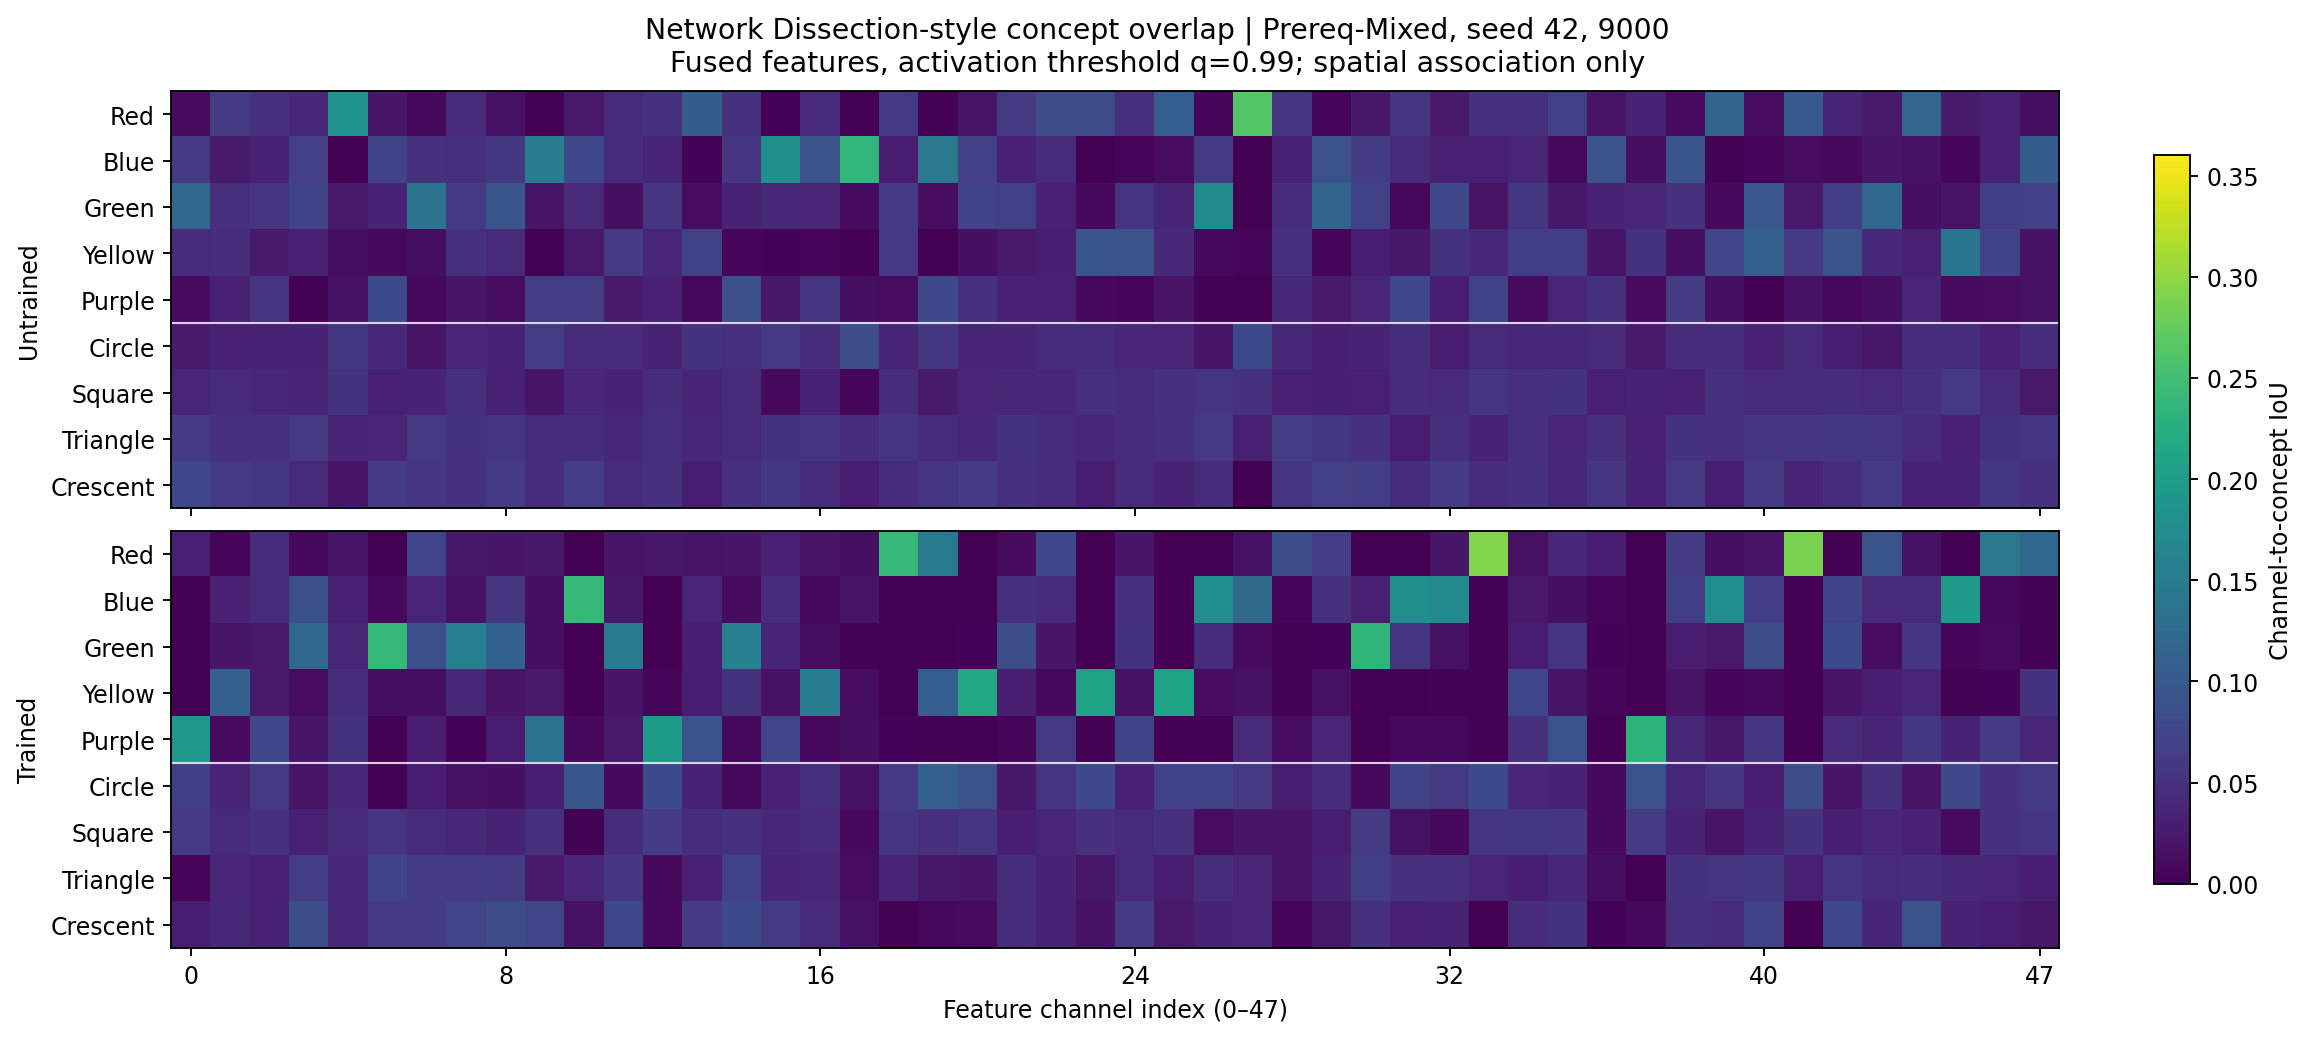

Figure: representation_dissection_channels.png


In [14]:
source = {}
for baseline in ("random", "trained"):
    d = read_csv(f"dissection_prereq_mixed_pair_focus_seed42_step9000_{baseline}.csv")
    part = d[(d.stage == "fused") & np.isclose(d["quantile"], 0.99)]
    concepts = [f"color_{color}" for color in colors]
    concepts += [f"shape_{shape}" for shape in shapes]
    pivot = part.pivot(index="concept", columns="unit", values="iou")
    matrix = pivot.reindex(index=concepts, columns=range(48)).to_numpy()
    assert matrix.shape == (9, 48) and np.isfinite(matrix).all()
    source[baseline] = matrix

fig, axes = plt.subplots(2, 1, figsize=(13.5, 6.0), sharex=True,
                         constrained_layout=True)
for ax, baseline in zip(axes, ("random", "trained")):
    image = ax.imshow(source[baseline], aspect="auto", vmin=0, vmax=0.36, cmap="viridis")
    ax.set_yticks(range(9), [*map(str.title, colors), *map(str.title, shapes)])
    ax.set_ylabel("Untrained" if baseline == "random" else "Trained")
    ax.axhline(4.5, color="white", alpha=0.8, linewidth=0.9)
axes[1].set_xticks([0, 8, 16, 24, 32, 40, 47])
axes[1].set_xlabel("Feature channel index (0–47)")
fig.colorbar(image, ax=axes, shrink=0.85, label="Channel-to-concept IoU")
fig.suptitle("Network Dissection-style concept overlap | Prereq-Mixed, seed 42, 9000\n"
             "Fused features, activation threshold q=0.99; spatial association only")
save_figure(fig, "representation_dissection_channels.png")

## 7. Spectral explanation clustering — interpretability controls

Cluster labels are *exploratory partitions*, not established concepts. We compute adjusted mutual information between supplied spectral-cluster labels and ground-truth Shape, Color, and correctness, separately for each seed/split/baseline/answer label. We also check whether graph connectivity and zero-map diagnostics are clean. No favorable clustering is assumed in advance.

In [15]:
cluster_records = []
for schedule in SCHEDULES:
    for seed in SEEDS:
        for step in STEPS:
            for split in SPLITS:
                for baseline in ("random", "trained"):
                    stem = f"{split}_{schedule}_seed{seed}_step{step}_{baseline}"
                    d = read_csv(f"explanation_clusters_{stem}.csv")

                    assert d.cluster.notna().all()
                    for label, part in d.groupby("label"):
                        clusters = part.cluster.astype(int)
                        cluster_records.append({
                            "schedule": schedule, "seed": seed, "step": step,
                            "split": split, "baseline": baseline, "label": int(label),
                            "n_maps": len(part), "n_clusters": clusters.nunique(),
                            "ami_shape": adjusted_mutual_info_score(part["shape"], clusters),
                            "ami_color": adjusted_mutual_info_score(part.color, clusters),
                            "ami_correct": adjusted_mutual_info_score(part.correct, clusters)
                        })
cluster_summary = pd.DataFrame(cluster_records)
save_table(cluster_summary, "spectral_cluster_semantic_associations.csv")
display(cluster_summary.query('step == 9000').groupby(["split", "baseline"])
        [["ami_shape", "ami_color", "ami_correct"]].agg(["mean", "std"]).round(3))

Table: spectral_cluster_semantic_associations.csv (240 rows)


ami_shape        ami_color        ami_correct       
                      mean    std      mean    std        mean    std
split   baseline                                                     
id_dev  random      -0.004  0.015     0.009  0.021      -0.004  0.006
        trained      0.011  0.033     0.008  0.027       0.004  0.017
ood_dev random      -0.004  0.012    -0.004  0.012      -0.000  0.015
        trained      0.010  0.029     0.010  0.029       0.001  0.019

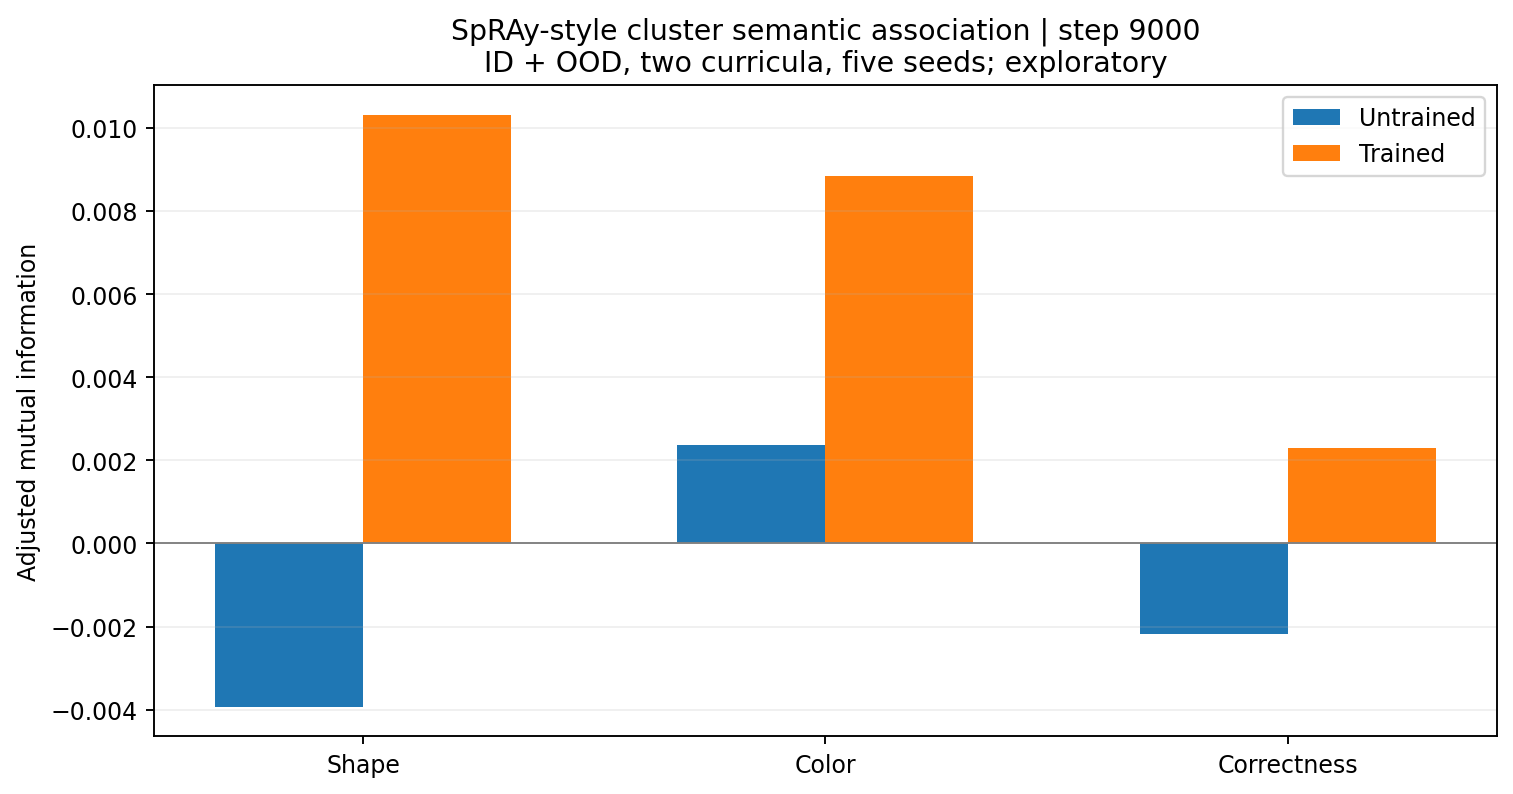

Figure: representation_spectral_cluster_association.png


In [16]:
subset = cluster_summary.query('step == 9000')
labels = ("ami_shape", "ami_color", "ami_correct")
fig, ax = plt.subplots(figsize=(9, 4.8))
x = np.arange(len(labels))
for i, baseline in enumerate(("random", "trained")):
    means = subset.query('baseline == @baseline').loc[:, labels].mean().to_numpy()
    ax.bar(x + (i - 0.5) * 0.32, means, width=0.32, label="Untrained" if baseline == "random" else "Trained")
ax.set_xticks(x, ["Shape", "Color", "Correctness"])
ax.set_ylabel("Adjusted mutual information")
ax.set_title("SpRAy-style cluster semantic association | step 9000\n"
             "ID + OOD, two curricula, five seeds; exploratory")
ax.axhline(0, color="gray", linewidth=0.8)
ax.grid(axis="y", alpha=0.2)
ax.legend()
fig.tight_layout()
save_figure(fig, "representation_spectral_cluster_association.png")

## 8. Actual saved explanation maps — scene and query verification

The original probing pipeline differentiated **the Yes-versus-No logit margin** with respect to image pixels, multiplied by `(image − background)`, summed over RGB, spatially averaged to 16×16, and L1-normalized. **Red indicates positive contribution to the local Yes margin; blue indicates negative contribution** for this attribution definition. It is not attention or proof of an object representation.

Example selection is deterministic: from final trained Prereq-Mixed, seed 42, choose six positive/negative and correct/incorrect cases, preferring different queried shapes and extreme final probabilities. The notebook records those decisions in `explanation_selected_examples.csv`, validates the same question IDs and map positions at every step, and renders the original scenes with `src.medium_visual_world.render.render`.

In [17]:
schedule, seed, split = "prereq_mixed_pair_focus", 42, "id_dev"

def explanation_data(step, baseline):
    stem = f"{split}_{schedule}_seed{seed}_step{step}_{baseline}"
    meta = read_csv(f"explanation_clusters_{stem}.csv").sort_values("map_index")
    maps = read_npz(f"explanation_maps_{stem}.npz", "maps")
    assert len(meta) == len(maps) == 160
    assert maps.shape[1:] == (16, 16)
    assert np.array_equal(meta.map_index.to_numpy(), np.arange(len(meta)))
    assert meta.explanation_method.eq("signed_grad_x_image_minus_background").all()

    return meta.reset_index(drop=True), maps

explanations = {
    (step, "trained"): explanation_data(step, "trained")
    for step in STEPS
}
explanations[(9000, "random")] = explanation_data(9000, "random")
reference = explanations[(9000, "trained")][0]
keys = ["scene_id", "task", "color", "shape", "label", "logic_case", "map_index"]
for other, _ in explanations.values():
    pd.testing.assert_frame_equal(other[keys], reference[keys], check_dtype=False)

cases = ((0, 0), (0, 1), (1, 1), (1, 0), (0, 0), (1, 1))
selection = []
for label, correct in cases:
    pool = reference[(reference.label == label) &
                     (reference.correct == correct) &
                     (~reference.map_index.isin(selection))]
    used_shapes = set(reference.loc[selection, "shape"])
    different = pool[~pool["shape"].isin(used_shapes)]
    if not different.empty:
        pool = different
    assert not pool.empty, f"No example available: label={label}, correct={correct}"
    # Prefer high-confidence errors, low-confidence correct negatives, etc.
    ascending = (bool(correct) if label == 0 else not bool(correct))
    pool = pool.sort_values(["prob_yes", "scene_id", "color", "shape"],
                            ascending=[ascending, True, True, True],
                            kind="mergesort")
    selection.append(int(pool.map_index.iloc[0]))
selected = reference.loc[selection, keys + ["prob_yes", "correct"]].copy()
save_table(selected, "explanation_selected_examples.csv")
display(selected)

Table: explanation_selected_examples.csv (6 rows)


,scene_id,task,color,shape,label,logic_case,map_index,prob_yes,correct
25,3b04251d16418d744b06b7f676299fa897f0e135bed7af...,pair,yellow,circle,0,attributes_separate,25,0.879018,0
66,ab252f1ecf50aa74c70fb1095f594662a3c4c0a4b6ad41...,pair,purple,square,0,attributes_separate,66,0.236701,1
51,a72999f4fc60bc4bb45a3ded7518028ca1bfe31dd6d4d3...,pair,blue,triangle,1,present_pair,51,0.832842,1
118,49cc71841d6e6b8efa43c448198166d47e8dc4bae3ec29...,pair,yellow,crescent,1,present_pair,118,0.292106,0
75,be1cbf5f3e07b1aaba53673f9d19ef3c94b5d8d128464d...,pair,green,triangle,0,attributes_separate,75,0.831295,0
50,ca04c0edb5b8f02bb865da5406f254ada8f428f03f6adb...,pair,yellow,circle,1,present_pair,50,0.944060,1


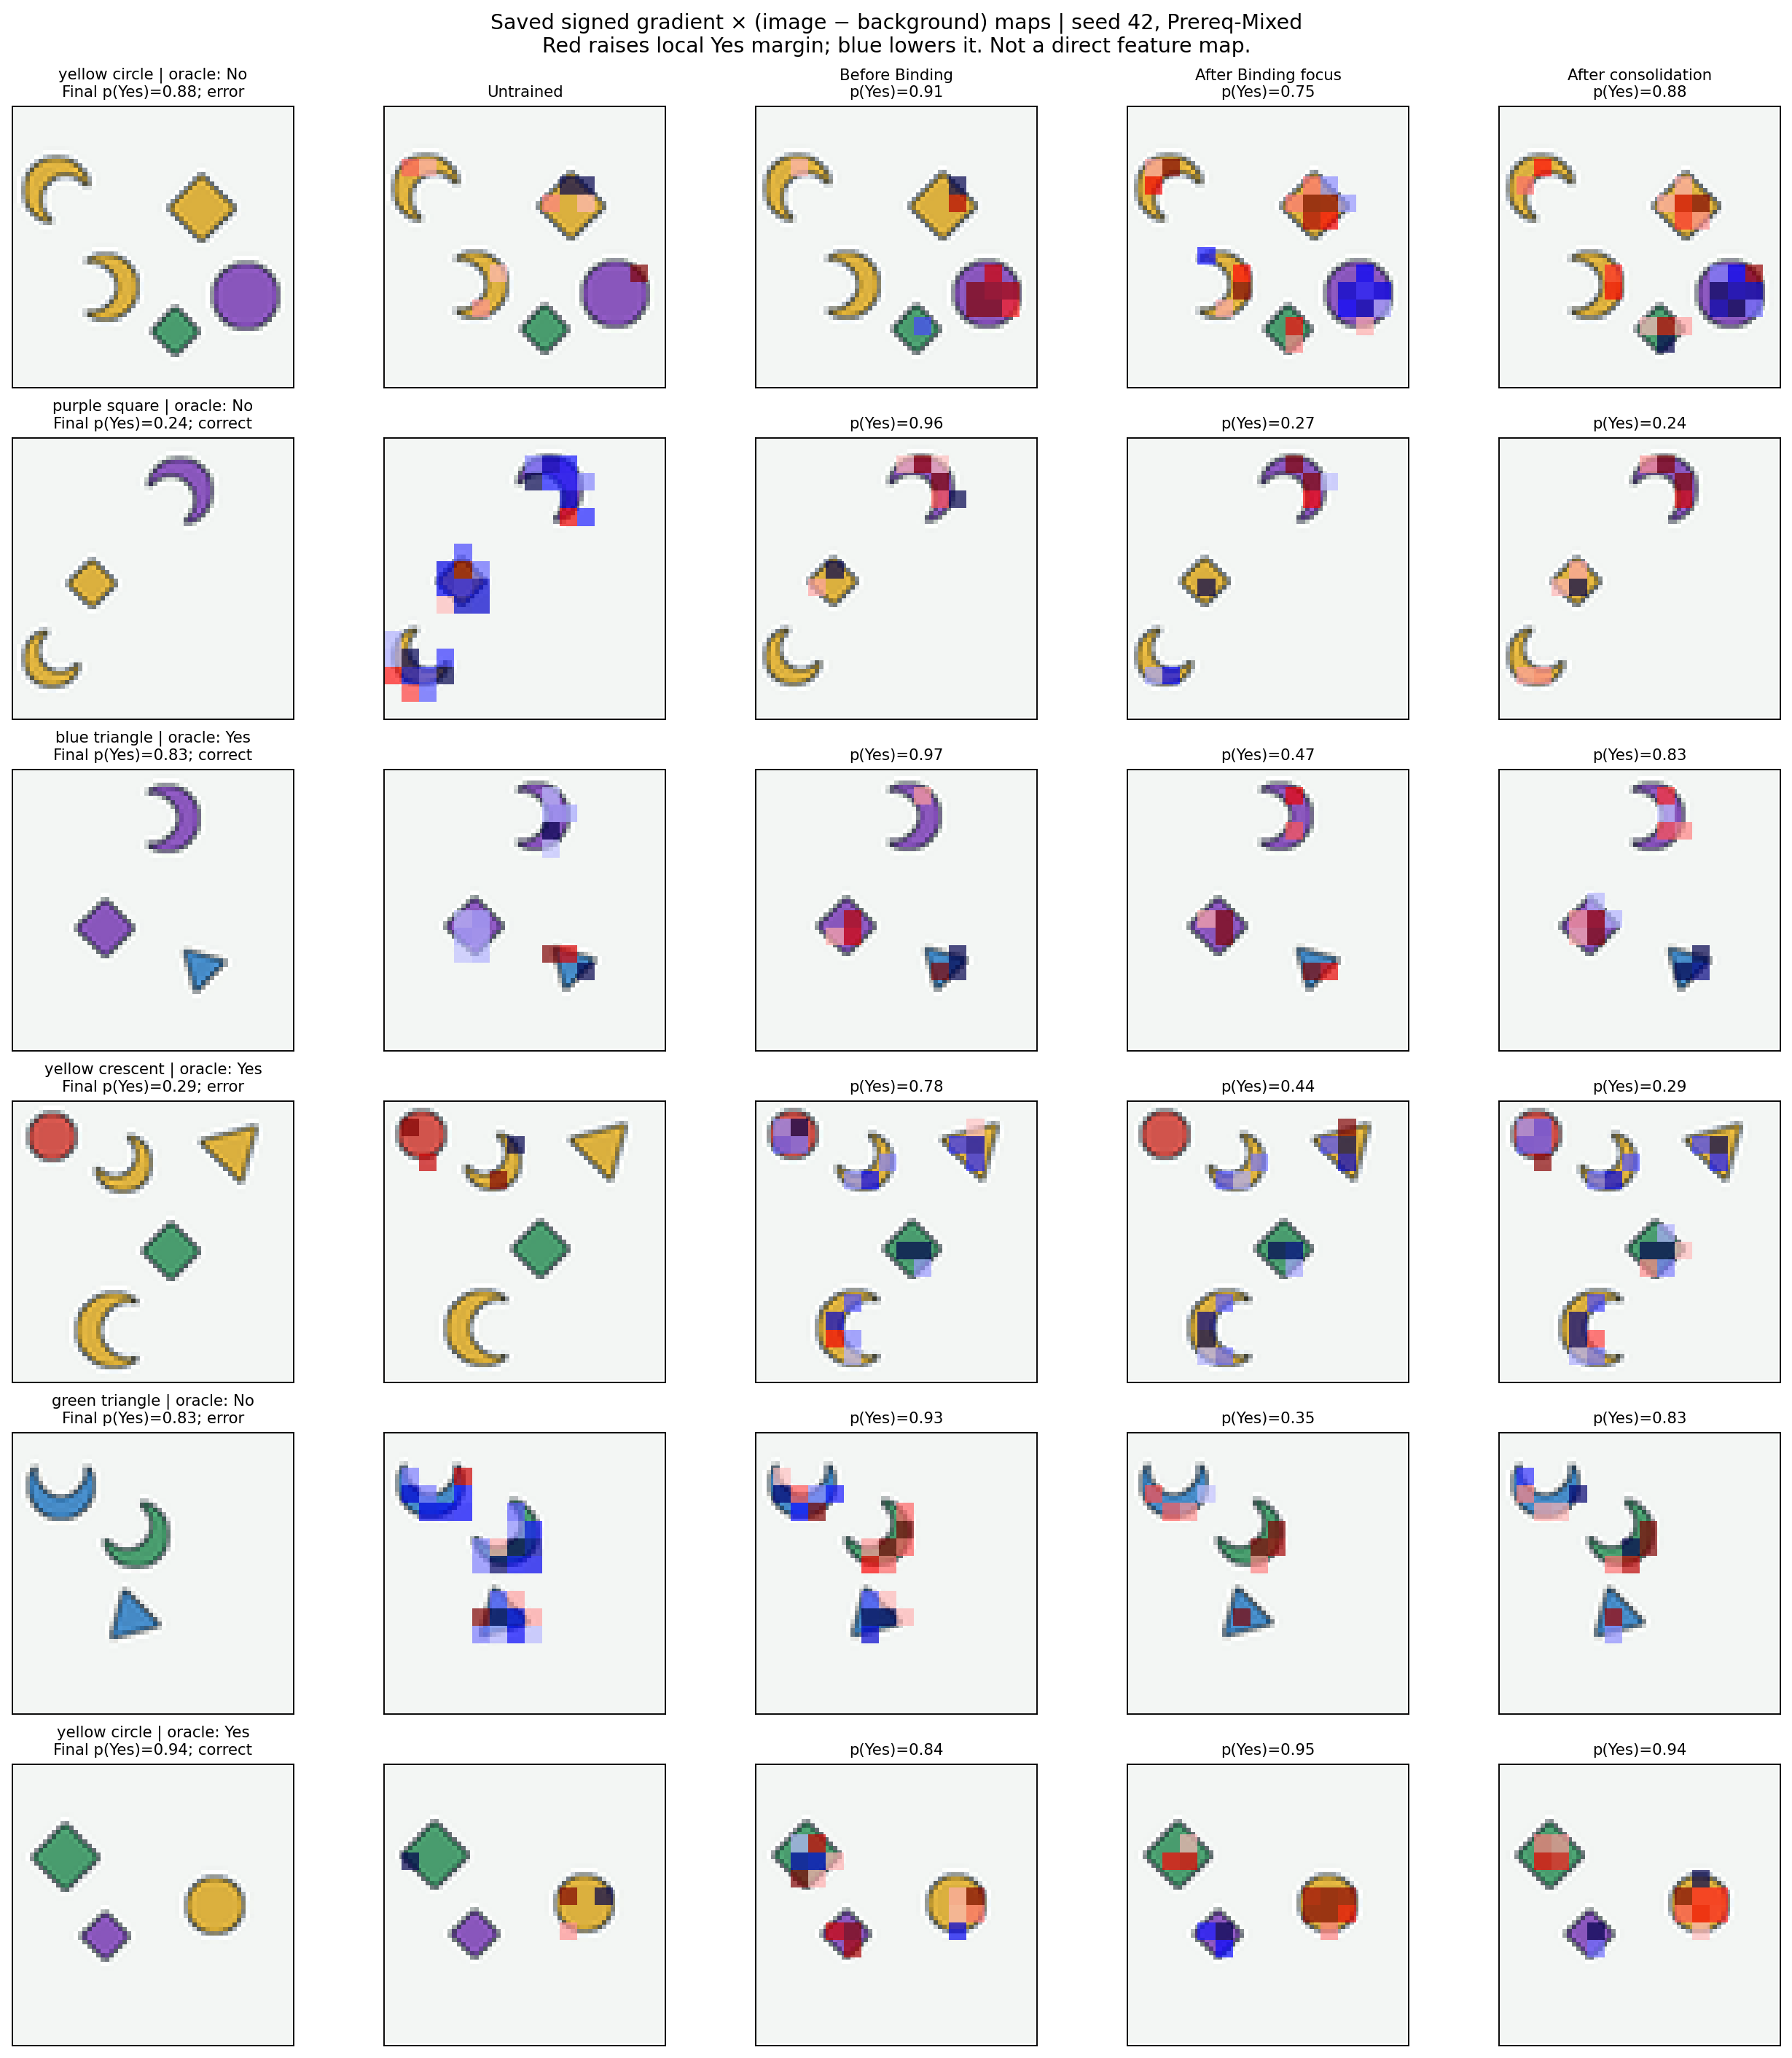

Figure: representation_explanation_evolution.png


In [18]:
fig, axes = plt.subplots(len(selection), 5,
                         figsize=(15, 2.75 * len(selection)),
                         constrained_layout=True)
for row_idx, map_index in enumerate(selection):
    item = reference.iloc[map_index]
    scene = scenes[item.scene_id]
    image = np.asarray(render(from_dict(scene)).convert("RGB"))
    assert image.shape == (64, 64, 3)
    axes[row_idx, 0].imshow(image, interpolation="nearest")
    actual = "Yes" if item.label else "No"
    verdict = "correct" if item.correct else "error"
    axes[row_idx, 0].set_title(
        f"{item.color} {item['shape']} | oracle: {actual}\n"
        f"Final p(Yes)={item.prob_yes:.2f}; {verdict}", fontsize=9
    )
    stages = ((9000, "random", "Untrained"),
              (5400, "trained", "Before Binding"),
              (7200, "trained", "After Binding focus"),
              (9000, "trained", "After consolidation"))
    for col_idx, (step, baseline, heading) in enumerate(stages, start=1):
        info, maps = explanations[(step, baseline)]
        map_values = maps[map_index]
        vmax = max(float(np.quantile(np.abs(map_values), 0.99)), 1e-8)
        ax = axes[row_idx, col_idx]
        ax.imshow(image, interpolation="nearest")
        ax.imshow(map_values, origin="upper", cmap="seismic",
                  vmin=-vmax, vmax=vmax,
                  alpha=np.where(np.abs(map_values) > vmax * 0.12, 0.7, 0),
                  extent=[0, 64, 64, 0], interpolation="nearest")
        subtitle = (f"\np(Yes)={info.iloc[map_index].prob_yes:.2f}"
                    if baseline == "trained" else "")
        ax.set_title((heading if row_idx == 0 else "") + subtitle, fontsize=9)
    for ax in axes[row_idx]:
        ax.set_xticks([])
        ax.set_yticks([])
fig.suptitle("Saved signed gradient × (image − background) maps | seed 42, Prereq-Mixed\n"
             "Red raises local Yes margin; blue lowers it. Not a direct feature map.",
             fontsize=12)
save_figure(fig, "representation_explanation_evolution.png")

## 9. Recreate the detailed CSV evidence from the earlier analysis pack

These tables retain the finer-grained evidence used in the research report. Every row is calculated from the saved *per-question* or *per-object* experiment files, not copied from an earlier summary.

The names correspond to the previous `representation_diagnostics_analysis_pack.zip`. Head-feature AUCs use the original, **signed** feature values. Hard Binding means both queried attributes exist in the scene and the target combination is permitted in training. OOD original-question predictions are matched by scene and exact target pair.

`shape_per_shape` in the legacy head statistics is **ROC AUC of the Shape-specific head score**, not per-shape classification accuracy. `hard_pair_failure_given_prereqs` uses only hard **negative** Binding queries where Color, Shape, and Conjunction are each answered correctly.

In [19]:
# 9.1: Head-feature discrimination across every seed, stage, and task.
head_details = []
for schedule in SCHEDULES:
    for seed in SEEDS:
        for step in STEPS:
            d = read_csv(f"same_scene_id_dev_{schedule}_seed{seed}_step{step}.csv")
            for task in ("color", "shape", "conjunction", "pair"):
                part = d[d.task == task]
                if task in ("color", "shape"):
                    part = part.drop_duplicates("question_key")
                if task in ("conjunction", "pair"):
                    part = part[~part.heldout_target.astype(bool)]
                subsets = [("all", part)]
                if task == "pair":
                    hard = part[(part.logic_case == "both_present") &
                                (~part.heldout_target.astype(bool))]
                    subsets.append(("hard", hard))
                for condition, subset in subsets:
                    for feature in range(8):
                        scores = subset[f"head_f{feature}"].to_numpy(dtype=float)
                        if subset.label.nunique() < 2 or np.ptp(scores) <= 1e-10:
                            auc = np.nan
                        else:
                            auc = float(roc_auc_score(subset.label, scores))
                        head_details.append({
                            "schedule": schedule, "seed": seed, "step": step,
                            "task": task, "condition": condition,
                            "feature": feature, "auc_raw": auc,
                            "auc_oriented": max(auc, 1 - auc) if np.isfinite(auc) else np.nan
                        })
head_details = pd.DataFrame(head_details)
save_table(head_details, "repr_head_feature_discriminability.csv")
display(head_details.query('step == 9000 and task == "pair" and condition == "hard"')
        .groupby("feature").auc_oriented.mean().round(3))

Table: repr_head_feature_discriminability.csv (1,200 rows)


feature
0    0.553
1    0.554
2    0.522
3    0.519
4    0.583
5    0.553
6    0.529
7    0.554
Name: auc_oriented, dtype: float64

In [20]:
# 9.2: Final-step task and cross-task head statistics.
def safe_auc(table, feature):
    return (float(roc_auc_score(table.label, table[feature]))
            if table.label.nunique() == 2 else np.nan)

head_stats_rows = []
for schedule in SCHEDULES:
    for seed in SEEDS:
        d = read_csv(f"same_scene_id_dev_{schedule}_seed{seed}_step9000.csv")
        c = d[d.task == "color"].drop_duplicates("question_key")
        s = d[d.task == "shape"].drop_duplicates("question_key")
        j = d[d.task == "conjunction"]
        p = d[(d.task == "pair") & (d.logic_case == "both_present") &
              (~d.heldout_target.astype(bool))]
        j_shape = j[j.logic_case.isin(("both_present", "missing_shape"))]
        p_yes = p[p.label == 1]
        p_no = p[p.label == 0]
        shape_scores = s[["scene_id", "shape", "head_f0", "correct"]].rename(
            columns={"head_f0": "shape_score", "correct": "shape_correct"})
        join = j.merge(shape_scores, on=["scene_id", "shape"], validate="many_to_one")
        missing_shape = join[join.logic_case == "missing_shape"]
        recognized = missing_shape[missing_shape.shape_correct.astype(bool)]
        shape_auc = {
            name: safe_auc(group, "head_f0")
            for name, group in s.groupby("shape")
        }
        hard_p = p[["scene_id", "color", "shape", "correct", "label", "prob_yes"]]
        # A hard-pair miss despite correct responses to each prerequisite.
        c_pred = c[["scene_id", "color", "correct"]].rename(
            columns={"correct": "color_ok"})
        s_pred = s[["scene_id", "shape", "correct"]].rename(
            columns={"correct": "shape_ok"})
        j_pred = j[["scene_id", "color", "shape", "correct"]].rename(
            columns={"correct": "conj_ok"})
        eligible = (hard_p.merge(c_pred, on=["scene_id", "color"])
                   .merge(s_pred, on=["scene_id", "shape"])
                   .merge(j_pred, on=["scene_id", "color", "shape"]))
        eligible = eligible[(eligible.label == 0) &
                            (eligible.color_ok == 1) &
                            (eligible.shape_ok == 1) &
                            (eligible.conj_ok == 1)]
        head_stats_rows.append({
            "schedule": schedule, "seed": seed,
            "auc_color_max": safe_auc(c, "head_f0"),
            "auc_shape_max": safe_auc(s, "head_f0"),
            "auc_conj_shape_max": safe_auc(j_shape, "head_f2"),
            "auc_conj_prob": safe_auc(j_shape, "prob_yes"),
            "shape_per_shape": str(list(shape_auc.items())),
            "max_shape_score_delta": float(np.max(np.abs(
                join.head_f2.to_numpy() - join.shape_score.to_numpy()))),
            "missing_shape_fail_given_shape_recognized":
                float((1 - recognized.correct).mean()),
            "shape_recognition_on_missing_shape":
                float(missing_shape.shape_correct.mean()),
            "hard_pair_auc": safe_auc(p, "prob_yes"),
            "hard_pair_balanced": float((p_yes.correct.mean() + p_no.correct.mean()) / 2),
            "hard_pair_neg_spec": float(p_no.correct.mean()),
            "hard_pair_pos_recall": float(p_yes.correct.mean()),
            "hard_pair_failure_given_prereqs": float((1 - eligible.correct).mean()),
            "n_eligible_hard": len(eligible)
        })
head_stats = pd.DataFrame(head_stats_rows)
save_table(head_stats, "repr_head_stats.csv")
display(head_stats.drop(columns="shape_per_shape").groupby("schedule").mean(numeric_only=True).round(4))

Table: repr_head_stats.csv (10 rows)


,seed,auc_color_max,auc_shape_max,auc_conj_shape_max,auc_conj_prob,max_shape_score_delta,missing_shape_fail_given_shape_recognized,shape_recognition_on_missing_shape,hard_pair_auc,hard_pair_balanced,hard_pair_neg_spec,hard_pair_pos_recall,hard_pair_failure_given_prereqs,n_eligible_hard
schedule,,,,,,,,,,,,,,
mixed,44.0,0.7158,0.5569,0.5553,0.6321,0.0,0.6863,0.6632,0.7083,0.6350,0.5258,0.7442,0.5871,880.2
prereq_mixed_pair_focus,44.0,0.7134,0.5532,0.5495,0.6323,0.0,0.6678,0.6372,0.7157,0.6431,0.5577,0.7286,0.5671,903.2


In [21]:
# 9.3: ID/OOD counterfactual outcomes and OOD shape-probe generalization.
counter_holdout_rows = []
probe_holdout_rows = []
for schedule in SCHEDULES:
    for seed in SEEDS:
        for step in STEPS:
            for split in SPLITS:
                counter = read_csv(
                    f"counterfactual_{split}_{schedule}_seed{seed}_step{step}.csv")
                counter["heldout"] = [
                    (c, s) in HOLDOUT for c, s in zip(counter.color, counter["shape"])
                ]
                for (edit, heldout), part in counter.groupby(["edit", "heldout"]):
                    counter_holdout_rows.append({
                        "schedule": schedule, "seed": seed, "step": step,
                        "split": split, "edit": edit, "heldout": bool(heldout),
                        "n": len(part), "both": float(part.both_correct.mean()),
                        "direction": float(part.direction_correct.mean()),
                        "delta": float(part.delta_yes.mean()),
                        "before": float(part.correct_before.mean()),
                        "after": float(part.correct_after.mean())
                    })
            p = read_csv(f"probe_predictions_{schedule}_seed{seed}_step{step}.csv")
            p = p[(p.split == "ood_dev") & (p.task == "shape") &
                  (p.stage == "encoder")].copy()
            p["heldout"] = [(c, s) in HOLDOUT for c, s in zip(p.color, p["shape"])]
            for (baseline, heldout), part in p.groupby(["baseline", "heldout"]):
                probe_holdout_rows.append({
                    "schedule": schedule, "seed": seed, "step": step,
                    "baseline": baseline, "heldout": bool(heldout),
                    "n": len(part), "accuracy": float(part.correct.mean())
                })
save_table(pd.DataFrame(counter_holdout_rows), "repr_counterfactual_holdout.csv")
save_table(pd.DataFrame(probe_holdout_rows), "repr_probe_ood_pair_holdout.csv")

Table: repr_counterfactual_holdout.csv (360 rows)
Table: repr_probe_ood_pair_holdout.csv (120 rows)


WindowsPath('C:/Users/Quoc Thai/Downloads/AI/AIO/Conquer/AIO Conquer 5 - visual_world/The-order-of-Learning/outputs/medium_world/experiments/representation_diagnostics/five_seeds/evidence_tables/repr_probe_ood_pair_holdout.csv')

In [22]:
# 9.4: Individual predictions for the original 400 OOD Binding questions.
original_ood = pd.DataFrame([{
    "scene_id": row["scene_id"],
    "task": "pair", "color": row["question"]["args"][0],
    "shape": row["question"]["args"][1], "original_label": int(row["label"])
} for row in ood_rows])

original_ood_results = []
for schedule in SCHEDULES:
    for seed in SEEDS:
        for step in STEPS:
            d = read_csv(f"same_scene_ood_dev_{schedule}_seed{seed}_step{step}.csv")
            p = d[d.task == "pair"].merge(
                original_ood, on=["scene_id", "task", "color", "shape"],
                validate="many_to_one")
            if len(p) != len(original_ood):
                raise ValueError("The OOD join did not recover exactly the original questions")
            p = p[["scene_id", "task", "color", "shape", "label", "prob_yes",
                   "prediction", "correct", "original_label"]].copy()
            p["schedule"] = schedule
            p["seed"] = seed
            p["step"] = step
            original_ood_results.append(p)
original_ood_predictions = pd.concat(original_ood_results, ignore_index=True)
save_table(original_ood_predictions, "repr_ood_original_pair_predictions.csv")

Table: repr_ood_original_pair_predictions.csv (12,000 rows)


WindowsPath('C:/Users/Quoc Thai/Downloads/AI/AIO/Conquer/AIO Conquer 5 - visual_world/The-order-of-Learning/outputs/medium_world/experiments/representation_diagnostics/five_seeds/evidence_tables/repr_ood_original_pair_predictions.csv')

In [23]:
# 9.5: Best Network Dissection unit for each concept and threshold.
dissection_rows = []
for schedule in SCHEDULES:
    for seed in SEEDS:
        for baseline in ("trained", "random"):
            d = read_csv(f"dissection_{schedule}_seed{seed}_step9000_{baseline}.csv")
            groups = ["stage", "concept", "quantile"]
            best = d.loc[d.groupby(groups).iou.idxmax()].copy()
            activated = best.activated_patches.to_numpy(dtype=float)
            targets = best.target_patches.to_numpy(dtype=float)
            # Largest possible IoU with fixed mask cardinalities.
            upper = np.minimum(activated, targets) / np.maximum(activated, targets)
            best["upper"] = upper
            best["iou_fraction_of_upper"] = np.divide(
                best.iou.to_numpy(), upper,
                out=np.zeros_like(upper), where=upper > 0)
            best["concept_group"] = best.concept.str.split("_").str[0]
            dissection_rows.append(best)
dissection_normalized = pd.concat(dissection_rows, ignore_index=True)
save_table(dissection_normalized, "repr_dissection_normalized.csv")

Table: repr_dissection_normalized.csv (1,080 rows)


WindowsPath('C:/Users/Quoc Thai/Downloads/AI/AIO/Conquer/AIO Conquer 5 - visual_world/The-order-of-Learning/outputs/medium_world/experiments/representation_diagnostics/five_seeds/evidence_tables/repr_dissection_normalized.csv')

In [24]:
# 9.6: SpRAy semantic and spatial associations, by seed and answer label.
def quadrant(y, x):
    return int(y >= 7.5) * 2 + int(x >= 7.5)

spray_rows = []
spatial_rows = []
for schedule in SCHEDULES:
    for seed in SEEDS:
        for step in STEPS:
            for split in SPLITS:
                for baseline in ("trained", "random"):
                    stem = f"{split}_{schedule}_seed{seed}_step{step}_{baseline}"
                    df = read_csv(f"explanation_clusters_{stem}.csv").sort_values("map_index")
                    maps = read_npz(f"explanation_maps_{stem}.npz", "maps")
                    values = np.abs(maps).reshape(len(maps), -1)
                    flat_pos = values.argmax(axis=1)
                    # Argmax uses integer patch coordinates; its half split is 8.
                    peak_quads = [int(y >= 8) * 2 + int(x >= 8)
                                  for y, x in zip(flat_pos // 16, flat_pos % 16)]
                    yy, xx = np.mgrid[0:16, 0:16]
                    mass = np.maximum(values.sum(axis=1), 1e-12)
                    cy = (np.abs(maps) * yy[None]).sum(axis=(1, 2)) / mass
                    cx = (np.abs(maps) * xx[None]).sum(axis=(1, 2)) / mass
                    center_quads = [quadrant(y, x) for y, x in zip(cy, cx)]
                    df["peak_quadrant"] = peak_quads
                    df["center_quadrant"] = center_quads
                    for label, part in df.groupby("label"):
                        group_id = part.cluster.astype(int)
                        accuracy_by_cluster = part.groupby("cluster").correct.mean()
                        common = {
                            "schedule": schedule, "seed": seed, "step": step,
                            "split": split, "baseline": baseline, "label": int(label)
                        }
                        spray_rows.append({
                            **common, "n": len(part), "classes": group_id.nunique(),
                            "acc_range": float(accuracy_by_cluster.max() -
                                               accuracy_by_cluster.min()),
                            "ami_shape": adjusted_mutual_info_score(part["shape"], group_id),
                            "ami_color": adjusted_mutual_info_score(part.color, group_id),
                            "ami_correct": adjusted_mutual_info_score(part.correct, group_id)
                        })
                        spatial_rows.append({
                            **common,
                            "ami_center_quadrant": adjusted_mutual_info_score(
                                part.center_quadrant, group_id),
                            "ami_peak_quadrant": adjusted_mutual_info_score(
                                part.peak_quadrant, group_id),
                            "ami_shape": adjusted_mutual_info_score(part["shape"], group_id),
                            "ami_color": adjusted_mutual_info_score(part.color, group_id)
                        })
save_table(pd.DataFrame(spray_rows), "repr_spray_cluster_assoc.csv")
save_table(pd.DataFrame(spatial_rows), "repr_spatial_cluster_assoc.csv")

Table: repr_spray_cluster_assoc.csv (240 rows)
Table: repr_spatial_cluster_assoc.csv (240 rows)


WindowsPath('C:/Users/Quoc Thai/Downloads/AI/AIO/Conquer/AIO Conquer 5 - visual_world/The-order-of-Learning/outputs/medium_world/experiments/representation_diagnostics/five_seeds/evidence_tables/repr_spatial_cluster_assoc.csv')

## 10. Earlier LR-reset comparison (optional)

Only a numerical comparison against the existing `schedule_comparison.json`. No changes to archived LR results.

In [25]:
history_path = PROJECT_ROOT / "outputs/medium_world/experiments/phase_aware_lr/schedule_comparison.json"
if history_path.is_file():
    with history_path.open(encoding="utf-8") as stream:
        historical = json.load(stream)
    historical_rows = []
    for run in historical.get("runs", []):
        if run.get("status") != "completed" or run.get("policy") != "constant":
            continue
        if run.get("schedule") not in SCHEDULES or run.get("seed") not in SEEDS:
            continue
        final = next((row for row in run["history"] if row["step"] == 9000), None)
        if final is None:
            continue
        for task, score in final["id_dev"]["by_template"].items():
            historical_rows.append({
                "schedule": run["schedule"], "seed": run["seed"],
                "task": task, "historical_accuracy": float(score)
            })
    historical_metrics = pd.DataFrame(historical_rows)
    compare = original_metrics.query('step == 9000').merge(historical_metrics, on=["schedule", "seed", "task"], validate="one_to_one")
    assert len(compare) == 2 * 5 * 4
    compare["delta_new_minus_historical"] = compare.accuracy - compare.historical_accuracy
    save_table(compare, "lr_reset_constant_checkpoint_comparison.csv")
    display(compare.groupby(["schedule", "task"])
            .delta_new_minus_historical.agg(["mean", "min", "max"]).round(5))
else:
    print("Historical LR-reset JSON absent. Cross-experiment comparison skipped;"
          " all evidence figures above remain fully computed from diagnostic outputs.")

Table: lr_reset_constant_checkpoint_comparison.csv (40 rows)


mean      min      max
schedule                task                                  
mixed                   color        0.00078  0.00000  0.00391
                        conjunction  0.00234  0.00000  0.01172
                        pair         0.00000  0.00000  0.00000
                        shape        0.00000  0.00000  0.00000
prereq_mixed_pair_focus color        0.00000  0.00000  0.00000
                        conjunction -0.00078 -0.00391  0.00000
                        pair         0.00156  0.00000  0.00781
                        shape        0.00000  0.00000  0.00000

## 11. Output inventory

The notebook stores figures and detailed tables in the experiment folder. Methodological notes belong in this notebook; machine/software details can be kept once in `README.md`.

## 10. Refined Shape probing: spatial and color-balanced decoders

This section regenerates its comparison figure directly from `refined_probe_metrics_*.csv` and the individual prediction files. Both curricula, all five seeds, and all three checkpoint steps are included. No old summary table or model retraining is needed.

In [26]:
refined_rows = []
for schedule in SCHEDULES:
    for seed in SEEDS:
        for step in STEPS:
            suffix = f'{schedule}_seed{seed}_step{step}'
            refined_rows.append(read_csv(f'refined_probe_metrics_{suffix}.csv'))
refined = pd.concat(refined_rows, ignore_index=True)
summary = (refined.groupby(['schedule', 'step', 'baseline', 'stage',
                            'regime', 'readout', 'split'])
           .accuracy.agg(['mean', 'std']).reset_index())
summary.to_csv(TABLE_DIR / 'refined_shape_probe_summary.csv', index=False)

paired_rows = []
comparison_pairs = (
    ('original_spatial_minus_mean', ('original', 'spatial'), ('original', 'mean')),
    ('balanced_spatial_minus_mean', ('recolored_balanced', 'spatial'),
     ('recolored_balanced', 'mean')),
    ('recolor_effect_spatial', ('recolored_balanced', 'spatial'),
     ('original', 'spatial')),
    ('recolor_effect_mean', ('recolored_balanced', 'mean'), ('original', 'mean')),
)
keys = ['schedule', 'seed', 'step', 'baseline', 'stage', 'split']
for label, (ra, fa), (rb, fb) in comparison_pairs:
    a = refined[(refined.regime == ra) & (refined.readout == fa)]
    b = refined[(refined.regime == rb) & (refined.readout == fb)]
    merged = a[keys + ['accuracy']].merge(
        b[keys + ['accuracy']], on=keys, suffixes=('_a', '_b'),
        validate='one_to_one')
    merged['contrast'] = label
    merged['difference_pp'] = 100 * (merged.accuracy_a - merged.accuracy_b)
    paired_rows.append(merged)
keys = ['schedule', 'seed', 'step', 'stage', 'regime', 'readout', 'split']
trained = refined[refined.baseline == 'trained']
random = refined[refined.baseline == 'random']
learned = trained[keys + ['accuracy']].merge(
    random[keys + ['accuracy']], on=keys, suffixes=('_a', '_b'),
    validate='one_to_one')
learned['contrast'] = 'trained_minus_random'
learned['difference_pp'] = 100 * (learned.accuracy_a - learned.accuracy_b)
learned['baseline'] = 'trained_vs_random'
paired_rows.append(learned)
paired = pd.concat(paired_rows, ignore_index=True)
paired.to_csv(TABLE_DIR / 'refined_shape_probe_paired_differences.csv', index=False)
display(summary[(summary.step == 9000) & (summary.stage == 'fused')])

,schedule,step,baseline,stage,regime,readout,split,mean,std
108,mixed,9000,random,fused,original,mean,id_dev,0.514188,0.023361
109,mixed,9000,random,fused,original,mean,ood_dev,0.464878,0.018450
110,mixed,9000,random,fused,original,spatial,id_dev,0.794129,0.010141
111,mixed,9000,random,fused,original,spatial,ood_dev,0.727370,0.014233
112,mixed,9000,random,fused,recolored_balanced,mean,id_dev,0.470157,0.022116
113,mixed,9000,random,fused,recolored_balanced,mean,ood_dev,0.486822,0.023254
114,mixed,9000,random,fused,recolored_balanced,spatial,id_dev,0.750294,0.018334
115,mixed,9000,random,fused,recolored_balanced,spatial,ood_dev,0.743113,0.015666
124,mixed,9000,shuffled_label_control,fused,recolored_balanced,spatial,id_dev,0.254892,0.012488
125,mixed,9000,shuffled_label_control,fused,recolored_balanced,spatial,ood_dev,0.247943,0.007222


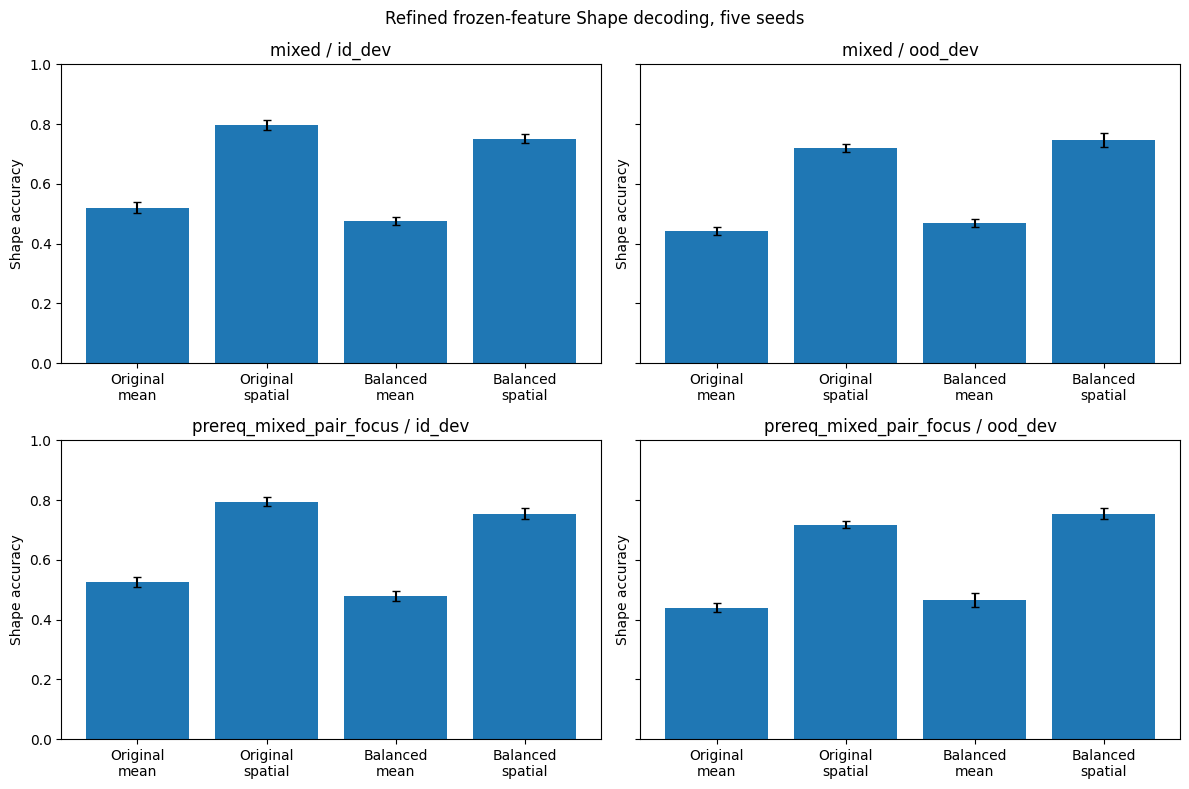

In [27]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharey=True)
for i, schedule in enumerate(SCHEDULES):
    for j, split in enumerate(SPLITS):
        part = summary[(summary.schedule == schedule)
                       & (summary.split == split)
                       & (summary.step == 9000)
                       & (summary.stage == 'fused')
                       & (summary.baseline == 'trained')]
        order = [('original', 'mean'), ('original', 'spatial'),
                 ('recolored_balanced', 'mean'),
                 ('recolored_balanced', 'spatial')]
        heights = [part[(part.regime == regime) &
                        (part.readout == readout)].iloc[0]['mean']
                   for regime, readout in order]
        errors = [part[(part.regime == regime) &
                       (part.readout == readout)].iloc[0]['std']
                  for regime, readout in order]
        axis = axes[i, j]
        axis.bar(range(4), heights, yerr=errors, capsize=3)
        axis.set_xticks(range(4), ['Original\nmean', 'Original\nspatial',
                                   'Balanced\nmean', 'Balanced\nspatial'])
        axis.set_title(f'{schedule} / {split}')
        axis.set_ylim(0, 1)
        axis.set_ylabel('Shape accuracy')
fig.suptitle('Refined frozen-feature Shape decoding, five seeds')
fig.tight_layout()
fig.savefig(FIG_DIR / 'representation_refined_shape_probe.png', dpi=170)
plt.show()

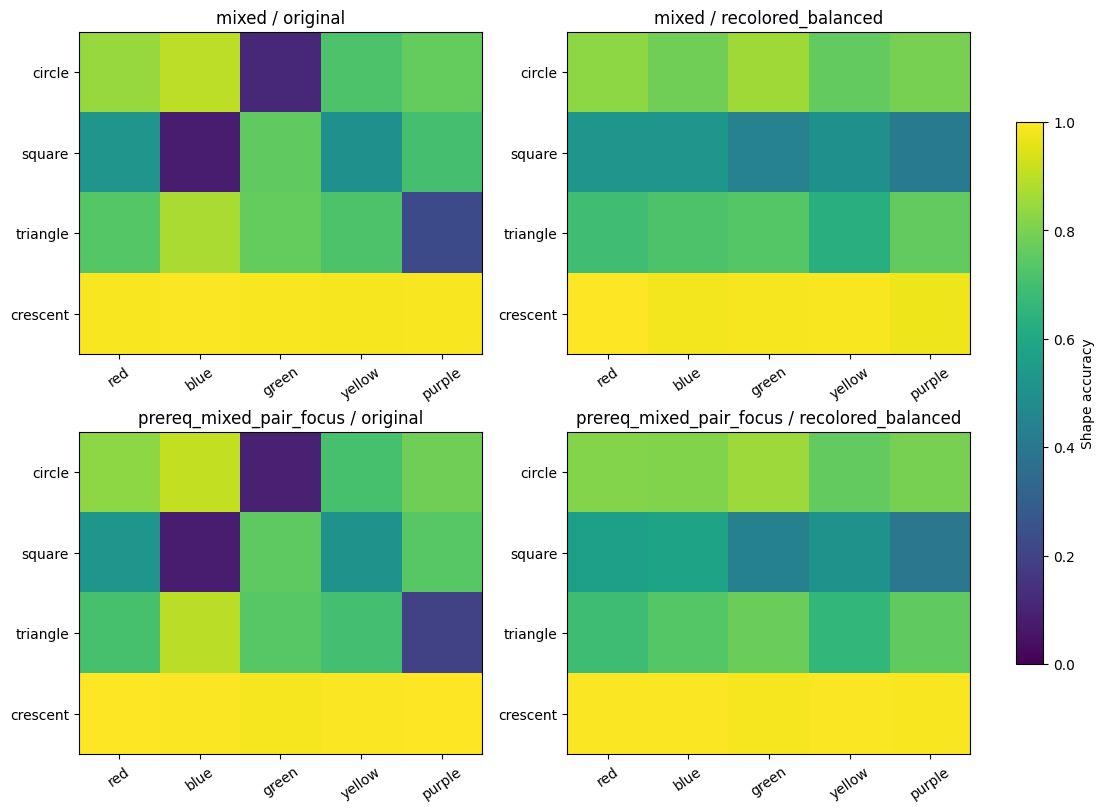

In [28]:
from src.medium_visual_world.world import SHAPES, COLORS

prediction_files = []
for schedule in SCHEDULES:
    for seed in SEEDS:
        suffix = f'{schedule}_seed{seed}_step9000'
        prediction_files.append(read_csv(f'refined_probe_predictions_{suffix}.csv'))
refined_pred = pd.concat(prediction_files, ignore_index=True)
combo = (refined_pred[
    (refined_pred.baseline == 'trained')
    & (refined_pred.stage == 'fused')
    & (refined_pred.split == 'ood_dev')
].groupby(['schedule', 'seed', 'regime', 'readout',
           'shape', 'color'], as_index=False)
 .correct.agg(['mean', 'size']).reset_index())
combo.to_csv(TABLE_DIR / 'refined_shape_probe_ood_by_combo.csv', index=False)

fig, axes = plt.subplots(2, 2, figsize=(11, 8), constrained_layout=True)
for i, schedule in enumerate(SCHEDULES):
    for j, regime in enumerate(('original', 'recolored_balanced')):
        part = combo[(combo.schedule == schedule)
                     & (combo.regime == regime)
                     & (combo.readout == 'spatial')]
        table = part.groupby(['shape', 'color'])['mean'].mean().unstack()
        matrix = table.reindex(index=SHAPES, columns=COLORS).to_numpy()
        im = axes[i, j].imshow(matrix, vmin=0, vmax=1, cmap='viridis')
        axes[i, j].set_xticks(range(len(COLORS)), COLORS, rotation=35)
        axes[i, j].set_yticks(range(len(SHAPES)), SHAPES)
        axes[i, j].set_title(f'{schedule} / {regime}')
fig.colorbar(im, ax=axes, shrink=0.75, label='Shape accuracy')
fig.savefig(FIG_DIR / 'representation_refined_shape_color_heatmap.png', dpi=170)
plt.show()

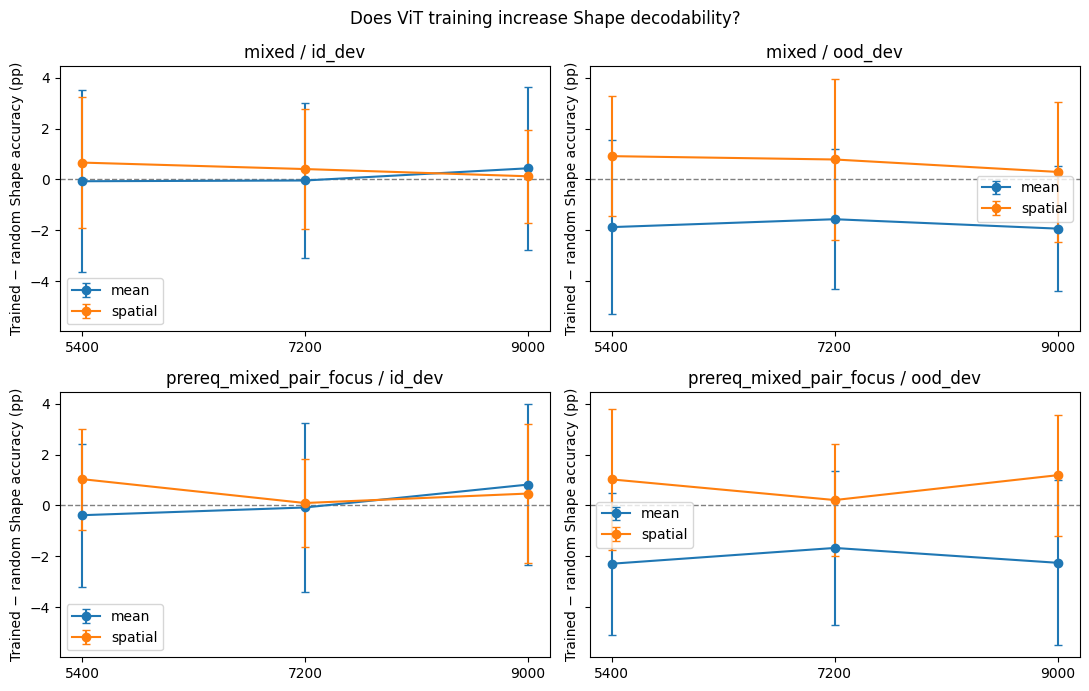

In [29]:
learned = paired[(paired.contrast == 'trained_minus_random')
                 & (paired.stage == 'fused')
                 & (paired.regime == 'recolored_balanced')]
fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharey=True)
for i, schedule in enumerate(SCHEDULES):
    for j, split in enumerate(SPLITS):
        axis = axes[i, j]
        part = learned[(learned.schedule == schedule)
                       & (learned.split == split)]
        for readout in ('mean', 'spatial'):
            by_step = (part[part.readout == readout]
                       .groupby('step').difference_pp.agg(['mean', 'std'])
                       .reindex(STEPS))
            axis.errorbar(STEPS, by_step['mean'], yerr=by_step['std'],
                          marker='o', capsize=3, label=readout)
        axis.axhline(0, linestyle='--', linewidth=1, color='gray')
        axis.set_title(f'{schedule} / {split}')
        axis.set_xticks(STEPS)
        axis.set_ylabel('Trained − random Shape accuracy (pp)')
        axis.legend()
fig.suptitle('Does ViT training increase Shape decodability?')
fig.tight_layout()
fig.savefig(FIG_DIR / 'representation_refined_trained_vs_random.png', dpi=170)
plt.show()

In [30]:
print("Figures:")
for path in sorted(FIG_DIR.glob("*.png")):
    print(" ", path.name)
print("Tables:")
for path in sorted(TABLE_DIR.glob("*.csv")):
    print(" ", path.name)

Figures:
  representation_dissection_channels.png
  representation_explanation_evolution.png
  representation_head_feature_auc.png
  representation_probe_color_shape_heatmap.png
  representation_refined_shape_color_heatmap.png
  representation_refined_shape_probe.png
  representation_refined_trained_vs_random.png
  representation_shape_radius_effect.png
  representation_spectral_cluster_association.png
  representation_stage_trajectories.png
Tables:
  counterfactual_run_level.csv
  dissection_best_unit_by_concept.csv
  explanation_selected_examples.csv
  head_feature_auc_by_seed.csv
  invariance_by_run.csv
  logical_consistency_by_run.csv
  lr_reset_constant_checkpoint_comparison.csv
  ood_shape_by_color_shape_seed.csv
  original_id_performance_recomputed.csv
  original_vs_same_scene_crosscheck.csv
  probe_heldout_accuracy_by_seed.csv
  refined_shape_probe_ood_by_combo.csv
  refined_shape_probe_paired_differences.csv
  refined_shape_probe_summary.csv
  repr_counterfactual_holdout.csv
 

## Interpretation

The historical evidence figures remain reproducible. The new Shape probes add a matched comparison of spatial versus mean-pooled features under the original and recolored, color-balanced diagnostic training distributions. The trained-versus-random contrast tests whether the learned encoder improves access to Shape information over initialization. The shuffled-label control checks whether a high-dimensional decoder can generalize without true Shape supervision.

Importantly, **the recolored diagnostic decoder has been exposed to all 20 Color–Shape combinations**; its OOD results measure accessibility of frozen features on different scenes, not novel Color–Shape generalization by that decoder. The underlying ViT was never retrained. A spatial probe improvement would motivate testing readout changes, not automatically prove the encoder has an explicit or causal Shape concept.